<center><font size=6> Bank Churn Prediction </font></center>

## Problem Statement

### Context

Businesses like banks which provide service have to worry about problem of 'Customer Churn' i.e. customers leaving and joining another service provider. It is important to understand which aspects of the service influence a customer's decision in this regard. Management can concentrate efforts on improvement of service, keeping in mind these priorities.

### Objective

You as a Data scientist with the  bank need to  build a neural network based classifier that can determine whether a customer will leave the bank  or not in the next 6 months.

### Data Description

* CustomerId: Unique ID which is assigned to each customer

* Surname: Last name of the customer

* CreditScore: It defines the credit history of the customer.
  
* Geography: A customer’s location
   
* Gender: It defines the Gender of the customer
   
* Age: Age of the customer
    
* Tenure: Number of years for which the customer has been with the bank

* NumOfProducts: refers to the number of products that a customer has purchased through the bank.

* Balance: Account balance

* HasCrCard: It is a categorical variable which decides whether the customer has credit card or not.

* EstimatedSalary: Estimated salary

* isActiveMember: Is is a categorical variable which decides whether the customer is active member of the bank or not ( Active member in the sense, using bank products regularly, making transactions etc )

* Exited : whether or not the customer left the bank within six month. It can take two values
** 0=No ( Customer did not leave the bank )
** 1=Yes ( Customer left the bank )

## Installing and Importing necessary libraries

In [10]:
!pip install tensorflow==2.18.0 imbalanced-learn==0.10.1 -q --user

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.0/226.0 kB 11.7 MB/s eta 0:00:00


In [206]:
!pip install scikit-learn==1.3.1 matplotlib===3.8.0 seaborn==0.13.1 numpy==1.26.4 pandas==2.2.2 -q --user

In [12]:
!pip install keras

In [13]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Library to split data
from sklearn.model_selection import train_test_split

# library to import to standardize the data
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Time related functions.
import time

# importing different functions to build models
import tensorflow as tf
from tensorflow import keras
from keras import backend
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout,BatchNormalization

# importing SMOTE
from imblearn.over_sampling import SMOTE

# importing metrics
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report


import random

# Library to avoid the warnings
import warnings
warnings.filterwarnings("ignore")

In [14]:
# Set the seed using keras.utils.set_random_seed. This will set:
# 1) `numpy` seed
# 2) backend random seed
# 3) `python` random seed
tf.keras.utils.set_random_seed(2)

# If using TensorFlow, this will make GPU ops as deterministic as possible,
# but it will affect the overall performance, so be mindful of that.
tf.config.experimental.enable_op_determinism()

## Loading the dataset

In [15]:
# Mounting the drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# Loading the dataset from drive
bankData = pd.read_csv("/content/drive/MyDrive/bank-1.csv")

## Data Overview

In [17]:
# Let's create a copy of the data
df = bankData.copy()

### Displaying the first few rows of the dataset

In [18]:
# Let's view the first 5 rows of the data
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Displaying the last few rows of the dataset

In [19]:
# Let's view the last 5 rows of the data
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


### Checking the shape of the dataset

In [20]:
# Checking the number of rows and columns in the data
df.shape

(10000, 14)

* The dataset has 10,000 rows and 14 columns

### Checking the data types of the columns of the dataset

In [21]:
# Let's check the data types of the columns in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


* There are 10,000 observations and 14 columns in the data.
* 3 columns are of the object datatype and 11 columns are numerical.

### Checking for duplicate and/or missing values

In [22]:
# Let's check for duplicate values in the data
df.duplicated().sum()

np.int64(0)

In [23]:
# Let's check for missing values in the data
round(df.isnull().sum() / df.isnull().count() * 100, 2)

,0
RowNumber,0.0
CustomerId,0.0
Surname,0.0
CreditScore,0.0
Geography,0.0
Gender,0.0
Age,0.0
Tenure,0.0
Balance,0.0
NumOfProducts,0.0


In [24]:
# Check if any columns/variables has null values
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


* There are no duplicate values in the dataset.
* And no null or missing values, so no treatement is required for this data.

In [25]:
# Let's view the statistical summary of the numerical columns in the data
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


Outside of the RowNumber, CustomerId and the Existed variable, there are only 8 numerical columns in the dataset and out of that only 5 are non-categorical.

* The minimum credit score ranges from poor to exxcellent from 350 to 850.
* Ages range from 18 to 92, with a mean and median around 37–39, indicating a slightly right-skewed distribution (mean > median, max is far from 75%). Most customers (50%) are between 32 and 44 years old. The high max (92) suggests a few older customers, potentially outliers.
* Tenure represents the number of years a customer has been with the organization (likely a bank). The range is 0 to 10 years, with a roughly uniform distribution (mean ≈ median). Most customers (50%) have tenures between 3 and 7 years. The min of 0 suggests new customers, and the max of 10 may indicate a capped tenure range.
* Salaries range from 11.58 to around 199,992, with high variability (large std). The mean and median are very close (~100,000), suggesting a fairly symmetric distribution, though the min (11.58) is unusually low, possibly an outlier or data entry error. Most customers (50%) have salaries between 51,002 and 149,388.
* This likely represents the number of financial products (e.g., accounts, loans) a customer has. Most customers have 1 or 2 products (75% have ≤2), with a mean of 1.53. The low std suggests limited variability. The max of 4 is rare, and the distribution is right-skewed (mean > median).
* Balances range from 0 to ~250,898, with high variability (large std). The 25th percentile at 0 indicates at least 25% of accounts have no balance, suggesting a significant number of inactive or low-activity accounts. The median (97,198.54) is much higher than the mean, indicating a right-skewed distribution with a few high-balance accounts driving up the mean.

In [26]:
# Let's check the number of unique values in each column
df.nunique()

,0
RowNumber,10000
CustomerId,10000
Surname,2932
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4


* Each value of the columns 'RowNumber' & 'CustomerId' is a unique identifier in the dataset. Hence we can drop these columns as it will not add any predictive power or value to the model.
* The 'Surname' column has 2932 unique surnames, so it makes no sense to keep this column either.

### Checking for unique values

In [27]:
# Check unique values for all the Object type variables
for i in df.describe(include=["object"]).columns:
    print("Unique values in", i, "are :")
    print(df[i].value_counts())
    print("*" * 50)

Unique values in Surname are :
Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Hull          1
Sturdee       1
Flannagan     1
Dwyer         1
Corby         1
Name: count, Length: 2932, dtype: int64
**************************************************
Unique values in Geography are :
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64
**************************************************
Unique values in Gender are :
Gender
Male      5457
Female    4543
Name: count, dtype: int64
**************************************************


* As mentioned above, we will get rid of Surname.

* France: 5,014 (50.14%) | Germany: 2,509 (25.09%) | Spain: 2,477 (24.77%) - The dominance of France suggests the organization (likely a bank) has a stronger presence or market share there. Investigating churn rates (Exited) or financial metrics (e.g., Balance, CreditScore) by geography could reveal regional trends. For instance, Germany might have higher balances due to economic factors, or Spain might show higher churn if economic instability is a factor.

* Male: 5,457 (54.57%) | Female: 4,543 (45.43%) - The slight male majority may reflect the customer base of the organization (e.g., a bank targeting professionals, where gender imbalances might exist). Analyzing churn or engagement by gender could uncover differences in retention strategies needed for each group.

In [28]:
# Check unique values for all the numerical int type variables
for i in df.describe(include=["int64"]).columns:
    print("Unique values in", i, "are :")
    print(df[i].value_counts())
    print("*" * 50)

Unique values in RowNumber are :
RowNumber
9984    1
9983    1
9982    1
9981    1
9980    1
       ..
5       1
4       1
3       1
2       1
1       1
Name: count, Length: 10000, dtype: int64
**************************************************
Unique values in CustomerId are :
CustomerId
15656710    1
15768163    1
15672754    1
15719276    1
15692664    1
           ..
15737888    1
15701354    1
15619304    1
15647311    1
15634602    1
Name: count, Length: 10000, dtype: int64
**************************************************
Unique values in CreditScore are :
CreditScore
850    233
678     63
655     54
705     53
667     53
      ... 
358      1
412      1
382      1
373      1
419      1
Name: count, Length: 460, dtype: int64
**************************************************
Unique values in Age are :
Age
37    478
38    477
35    474
36    456
34    447
     ... 
84      2
82      1
88      1
85      1
83      1
Name: count, Length: 70, dtype: int64
***************************

In [29]:
# Check unique values for all the numerical float type variables
for i in df.describe(include=["float64"]).columns:
    print("Unique values in", i, "are :")
    print(df[i].value_counts())
    print("*" * 50)

Unique values in Balance are :
Balance
0.00         3617
130170.82       2
105473.74       2
159397.75       1
144238.70       1
             ... 
108698.96       1
238387.56       1
111833.47       1
126619.27       1
138734.94       1
Name: count, Length: 6382, dtype: int64
**************************************************
Unique values in EstimatedSalary are :
EstimatedSalary
24924.92     2
121505.61    1
89874.82     1
72500.68     1
182692.80    1
            ..
188377.21    1
55902.93     1
4523.74      1
102195.16    1
2465.80      1
Name: count, Length: 9999, dtype: int64
**************************************************


* Looks like among numerical variables most of them are continous and some like HasCrCard and IsActiveNumber are binary aside from the dependent variable Exited.
* But It seems like NumOfProducts can be easily converted to categories or dummies and remove the one with value 4 since it only has 60 records attached and seems useless.

In [30]:
df["Exited"].value_counts(1)

,proportion
Exited,
0,0.7963
1,0.2037


* The Exited column shows a 20.37% churn rate, with 7,963 customers staying and 2,037 leaving. The imbalanced distribution (4:1 ratio) suggests a stable but vulnerable customer base, requiring targeted analysis of numerical features to uncover churn drivers.

## <a name='link2'>Exploratory Data Analysis (EDA) Summary</a>

### **Note**: The EDA section has been covered in detail in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the <a href = #link1>appendix section</a>.

**The below functions need to be defined to carry out the Exploratory Data Analysis.**

In [31]:
# Function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [32]:
# Function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [33]:
### Function to plot distributions


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [34]:
# function to plot stacked bar chart


def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 1, 5))
    plt.legend(
        loc="lower left",
        frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

## Data Preprocessing

### Column Binning

In [35]:
# RowNumber, CustomerId is unique for each candidate and might not add value to modeling
df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1, inplace=True) # Surname doesn't add any value too

In [36]:
# Create a copy of data post pruning the variables
data = df.copy()

In [37]:
# Check the number of uniqie credit card scores
data["CreditScore"].nunique()

460

In [38]:
# Define the bin function for credit scores
def bin(x):
    if x in range(300,580):
      return 'Poor'
    elif x in range(580,670):
      return 'Fair'
    elif x in range(670,740):
      return 'Good'
    elif x in range(740,800):
      return 'Very Good'
    else:
      return 'Excellent'

* Just created a function to showcase we can bin CreditScore and NumOfProducts column into categories but since Neural Network performs exceptionally well with the non-linear data, for simplicity I would skip that step.

### Dummy Variable Creation | Encoding the categorical variables

In [39]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [40]:
# Encoding Object type categorical variables without dropping the first column from the dummies
data = pd.get_dummies(data, columns=["Geography", "Gender"], drop_first=True)
data = data.astype(float)
data.tail()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
9995,771.0,39.0,5.0,0.00,2.0,1.0,0.0,96270.64,0.0,0.0,0.0,1.0
9996,516.0,35.0,10.0,57369.61,1.0,1.0,1.0,101699.77,0.0,0.0,0.0,1.0
9997,709.0,36.0,7.0,0.00,1.0,0.0,1.0,42085.58,1.0,0.0,0.0,0.0
9998,772.0,42.0,3.0,75075.31,2.0,1.0,0.0,92888.52,1.0,1.0,0.0,1.0
9999,792.0,28.0,4.0,130142.79,1.0,1.0,0.0,38190.78,0.0,0.0,0.0,0.0


* Encoded categorical variables Gender and Geography and dropped the first column while creating the dummies.


### Data Normalization

In [41]:
# Standardizing the numerical variables to zero mean and unit variance.
transformer = StandardScaler()
data[["EstimatedSalary", "Age", "Tenure", "Balance", "CreditScore", "NumOfProducts"]] = transformer.fit_transform(data[["EstimatedSalary", "Age", "Tenure", "Balance", "CreditScore", "NumOfProducts"]])

* Normalized numerical variables/columns using scaling technique. This is also a crucial step in dataprocessing.

### Train-validation-test Split

In [42]:
X = data.drop(['Exited'],axis=1) # Get independent variables
y = df['Exited'] # Get dependent/target variable

In [43]:
# Split the data (70-20-10 split with stratification)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2222, stratify=y_temp, random_state=42)  # 0.2222 of 90% = 20% of total

In [44]:
# Printing the shapes | Check the size of each train, validation & testing datasets after split
print(X_train.shape,y_train.shape)
print(X_val.shape,y_val.shape)
print(X_test.shape,y_test.shape)

(7000, 11) (7000,)
(2000, 11) (2000,)
(1000, 11) (1000,)


* Training on most samples (70%) and then evaluating on validation with 20% val dataset and then in the end predicting on 10% test dataset.

### Utility functions

In [45]:
def plot(history, name):
    """
    Function to plot loss/accuracy

    history: an object which stores the metrics and losses.
    name: can be one of Loss or Accuracy
    """
    fig, ax = plt.subplots() #Creating a subplot with figure and axes.
    plt.plot(history.history[name]) #Plotting the train accuracy or train loss
    plt.plot(history.history['val_'+name]) #Plotting the validation accuracy or validation loss

    plt.title('Model ' + name.capitalize()) #Defining the title of the plot.
    plt.ylabel(name.capitalize()) #Capitalizing the first letter.
    plt.xlabel('Epoch') #Defining the label for the x-axis.
    fig.legend(['Train', 'Validation'], loc="outside right upper") #Defining the legend, loc controls the position of the legend.

In [46]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(
    model, predictors, target, threshold=0.5
):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors) > threshold
    # pred_temp = model.predict(predictors) > threshold
    # # rounding off the above values to get classes
    # pred = np.round(pred_temp)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='weighted')  # to compute Recall
    precision = precision_score(target, pred, average='weighted')  # to compute Precision
    f1 = f1_score(target, pred, average='weighted')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,},
        index=[0],
    )

    return df_perf

In [47]:
def make_confusion_matrix(actual_targets, predicted_targets):
    """
    To plot the confusion_matrix with percentages

    actual_targets: actual target (dependent) variable values
    predicted_targets: predicted target (dependent) variable values
    """
    cm = confusion_matrix(actual_targets, predicted_targets)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(cm.shape[0], cm.shape[1])

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

In [48]:
# Currently we are using Recall metric to build all the models
train_metric_df = pd.DataFrame(columns=["recall"])
valid_metric_df = pd.DataFrame(columns=["recall"])

## Model Building

### Model Evaluation Criterion

**A model can make wrong predictions in the following ways:**
* Predicting the customers will churn or leave the bank in next 6 months, when they are not going to leave.
* Predicting the customers will not churn or leave the bank in next 6 months, when they are in fact going to leave.

**Which case is more important?**

* The most important case for the bank should be to make sure there's few to zero False Negatives because if the model predicts that customers won't churn in next 6 months (Negative), and they actually do churn or leave the bank in next 6 months (False), then it will be the worst case scenario and bad outcome for the bank.
* Because in other scenario i.e. if we predict that the customer will churn in 6 months but in fact they won't leave, then it has no negative impact on the bank itself.
* False negatives lead to revenue loss (e.g., high-balance customers), reduced customer lifetime value, and reputational risks.
* Hence lowering the false negatives is the most important for this bank.

**How to reduce this loss i.e need to reduce False Negatives?**

* Using Recall metric we should be able to reduce the loss/False Negatives.
* Although increasing F1Score in general is a win-win by reducing both False Postives and False Negatives, it is not as crucial as increasing Recall for this particular problem.
* Since reducing False Negatives should be the number one priority, we should use Recall as the core metric for all the models.


In [49]:
# Calculate class weights for imbalanced dataset
cw = (y_train.shape[0]) / np.bincount(y_train)

# Create a dictionary mapping class indices to their respective class weights
cw_dict = {}
for i in range(cw.shape[0]):
    cw_dict[i] = cw[i]

cw_dict

{0: np.float64(1.2558306422676713), 1: np.float64(4.908835904628331)}

* Class weight attribute will help in balancing the dataset by giving some weightage on the minority class.

In [50]:
# Defining the batch size, epochs & metric upfront as we'll be using the same values for all models
epochs = 50
batch_size = 32
metric = keras.metrics.Recall()

* Keping the above parameters static for all the models.

### Neural Network with SGD Optimizer

In [51]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources
tf.keras.backend.clear_session()

In [52]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [53]:
# Initialize the neural network
model_0 = Sequential()
# Adding the input layer with 16 neurons and ReLU activation
model_0.add(Dense(16, activation='relu', input_dim=X_train.shape[1]))
# Adding a hidden layer with 8 neurons and ReLU activation
model_0.add(Dense(8, activation='relu'))
# Adding the output layer with 1 neuron and sigmoid activation
model_0.add(Dense(1, activation='sigmoid'))

In [54]:
# Let's use SGD as the optimizer with minimal learning rate
optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)

In [55]:
# Compile the model with binary cross entropy as loss function and recall as the metric
model_0.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [56]:
model_0.summary() # Summarize the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [57]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_0 = model_0.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=cw_dict)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 1.4228 - recall: 0.8839 - val_loss: 0.7713 - val_recall: 0.8501
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 1.3996 - recall: 0.8098 - val_loss: 0.7455 - val_recall: 0.8108
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1.3854 - recall: 0.7653 - val_loss: 0.7285 - val_recall: 0.7666
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1.3752 - recall: 0.7241 - val_loss: 0.7167 - val_recall: 0.7420
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 1.3671 - recall: 0.6932 - val_loss: 0.7079 - val_recall: 0.7273
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.3600 - recall: 0.6807 - val_loss: 0.7012 - val_recall: 0.7002
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.3534 - recall: 0.6728 - val_loss: 0.6958 - val_recall: 0.6929
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 1.3472 - recall: 0.6637 - val_loss: 0.6913 - val_recall: 0.6929
Epoch

#### Analyze Loss function and Recall

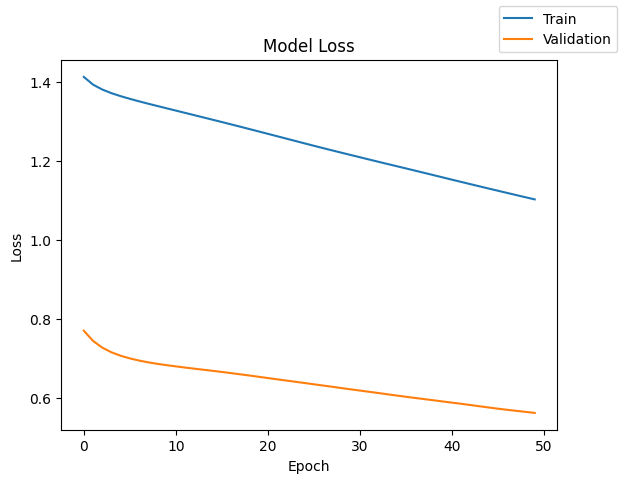

In [58]:
plot(history_0,'loss') # Visualize Loss

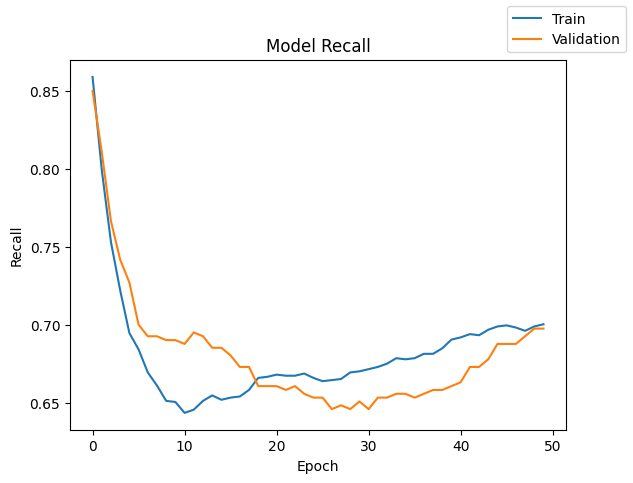

In [59]:
plot(history_0,'recall') # Visualize Recall

In [60]:
# Using pre-defined performace classifier to return metrics for training set
model_0_train_perf = model_performance_classification(model_0, X_train, y_train)
model_0_train_perf

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.764,0.764,0.816162,0.780622


In [61]:
# Predicting the results on the training set using 0.5 as a threshold
y_train_pred = model_0.predict(X_train)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[False],
       [False],
       [ True],
       ...,
       [False],
       [False],
       [False]])

In [62]:
# Using pre-defined performace classifier to return metrics for validation set
model_0_valid_perf = model_performance_classification(model_0, X_val, y_val)
model_0_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.774,0.774,0.820146,0.78901


In [63]:
# Predicting the results on the validation set using 0.5 as a threshold
y_val_pred = model_0.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [ True],
       [False],
       [ True]])

In [64]:
# Add model name and recall performance to the metrics list
model_name = "NN with SGD"

train_metric_df.loc[model_name] = recall_score(y_train, y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val, y_val_pred)

#### Classification report

In [65]:
# Classification report on training dataset
cr = classification_report(y_train, y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.78      0.84      5574
           1       0.45      0.70      0.55      1426

    accuracy                           0.76      7000
   macro avg       0.68      0.74      0.69      7000
weighted avg       0.82      0.76      0.78      7000



In [66]:
# Classification report on validation dataset
cr=classification_report(y_val, y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.79      0.85      1593
           1       0.46      0.70      0.56       407

    accuracy                           0.77      2000
   macro avg       0.69      0.75      0.70      2000
weighted avg       0.82      0.77      0.79      2000



#### Confusion matrix

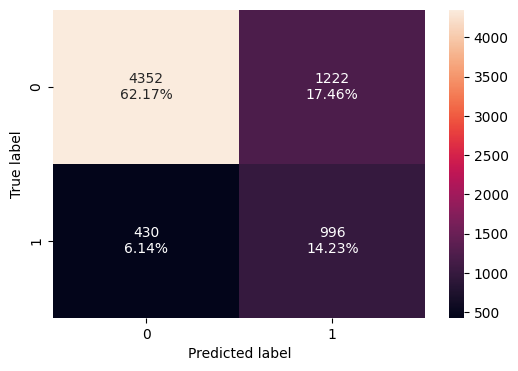

In [67]:
# Check model performance on training dataset
make_confusion_matrix(y_train, y_train_pred)

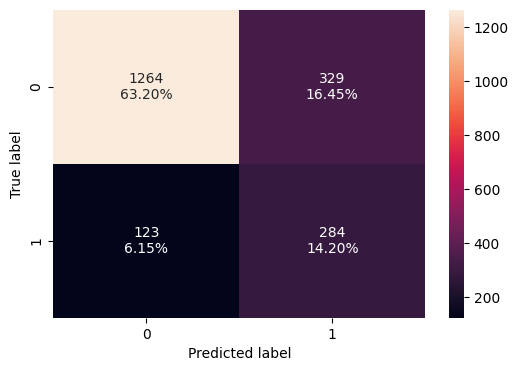

In [68]:
# Check model performance on validation dataset
make_confusion_matrix(y_val, y_val_pred)

* Class weights helped balanced the dataset with minority class a bit.
* Loss continued to decrease for both training and validation but the gap is still big.
* We can see if Adam optimizer performs better

## Model Performance Improvement

### Neural Network with Adam Optimizer

In [69]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources
tf.keras.backend.clear_session()

In [70]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [71]:
# Initialize the neural network
model_1 = Sequential()
# Adding the input layer with 16 neurons and ReLU activation
model_1.add(Dense(16,activation='relu',input_dim = X_train.shape[1]))
# Adding the input layer with 16 neurons and ReLU activation
model_1.add(Dense(8,activation='relu'))
# Adding the output layer with 1 neuron and Sigmoid activation
model_1.add(Dense(1, activation = 'sigmoid'))

In [72]:
# Let's use Adam optimizer with minimal learning rate
optimizer = tf.keras.optimizers.Adam(0.01)

In [73]:
# Compile the model with binary cross entropy as loss function and recall as the metric
model_1.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [74]:
model_1.summary() # Summarize the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_1 = model_1.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=cw_dict)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.1837 - recall: 0.7104 - val_loss: 0.4552 - val_recall: 0.6609
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.9423 - recall: 0.7574 - val_loss: 0.4388 - val_recall: 0.6683
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.9081 - recall: 0.7635 - val_loss: 0.4395 - val_recall: 0.6781
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.8964 - recall: 0.7630 - val_loss: 0.4382 - val_recall: 0.6732
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.8891 - recall: 0.7594 - val_loss: 0.4381 - val_recall: 0.6708
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8845 - recall: 0.7608 - val_loss: 0.4398 - val_recall: 0.6830
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.8795 - recall: 0.7734 - val_loss: 0.4391 - val_recall: 0.6757
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.8763 - recall: 0.7714 - val_loss: 0.4345 - val_recall: 0.6634
Epoch 9/

#### Analyze Loss function and Recall

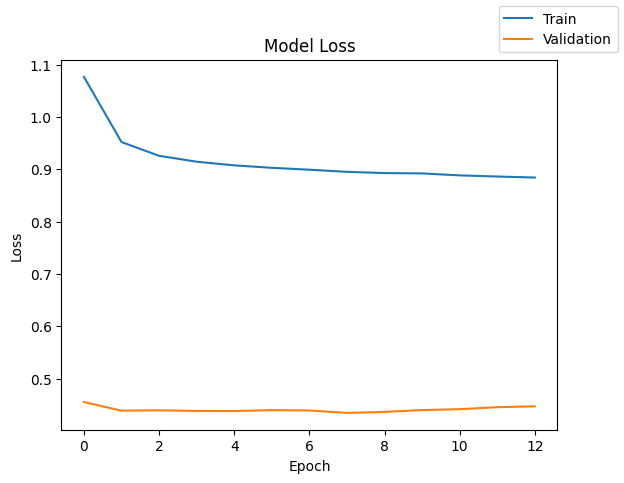

In [76]:
plot(history_1,'loss') # Visualize Loss

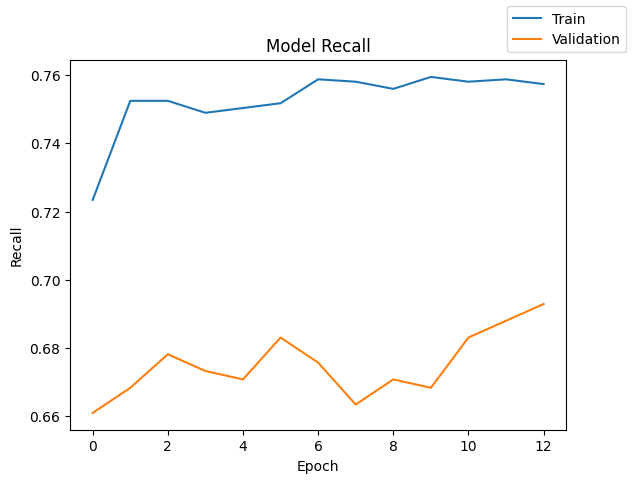

In [77]:
plot(history_1,'recall') # Visualize Recall

In [78]:
# Using pre-defined performace classifier to return metrics for training set
model_1_train_perf = model_performance_classification(model_1, X_train, y_train)
model_1_train_perf

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.829571,0.829571,0.850292,0.836926


In [79]:
# Predicting the results using 0.5 as the threshold
y_train_pred = model_1.predict(X_train)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[False],
       [False],
       [ True],
       ...,
       [ True],
       [False],
       [False]])

In [80]:
# Using pre-defined performace classifier to return metrics for validation set
model_1_valid_perf = model_performance_classification(model_1, X_val, y_val)
model_1_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.812,0.812,0.831261,0.819358


In [81]:
# Predicting the results using 0.5 as the threshold
y_val_pred = model_1.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [False],
       [False],
       [ True]])

In [82]:
# Add model name and recall performance to the metrics list
model_name = "NN with Adam"

# Fit model with helping functions
train_metric_df.loc[model_name] = recall_score(y_train,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

#### Classification report

In [83]:
# Classification report on training dataset
cr=classification_report(y_train,y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.92      0.86      0.89      5574
           1       0.56      0.72      0.63      1426

    accuracy                           0.83      7000
   macro avg       0.74      0.79      0.76      7000
weighted avg       0.85      0.83      0.84      7000



In [84]:
# Classification report on validation dataset
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.85      0.88      1593
           1       0.53      0.66      0.59       407

    accuracy                           0.81      2000
   macro avg       0.72      0.76      0.73      2000
weighted avg       0.83      0.81      0.82      2000



#### Confusion matrix

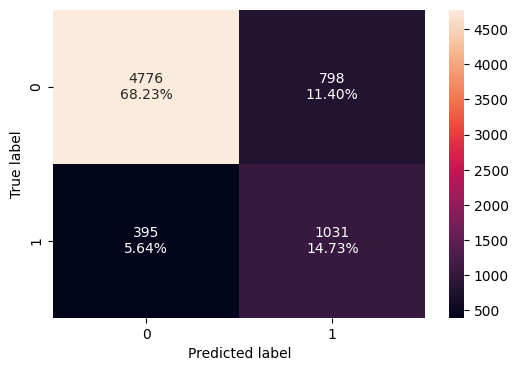

In [85]:
# Check model performance on training dataset
make_confusion_matrix(y_train, y_train_pred)

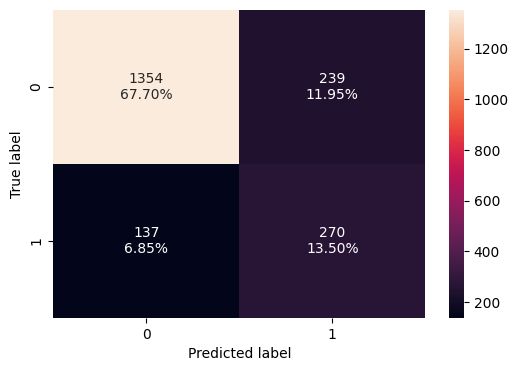

In [86]:
# Check model performance on training dataset
make_confusion_matrix(y_val,y_val_pred)

* You can clearly see the huge difference in overall Recall on validation set. It increased from 0.77 to 0.81. And in F1 Score.
* This model is clearly overfitting but it's still a major improvement over SGD optimizer.
* Let's add dropout and see if it increases

### Neural Network with Adam Optimizer and Dropout

In [87]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [88]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [89]:
# Initialize the neural network
model_2 = Sequential()

# Adding a hidden layer with 16 neurons and ReLU activation
model_2.add(Dense(16, activation='relu'))
# Adding dropout
model_2.add(Dropout(0.4))
# Adding a hidden layer with 8 neurons and ReLU activation
model_2.add(Dense(8, activation='relu'))
# Adding dropout
model_2.add(Dropout(0.2))
# Adding the output layer with 1 neuron and sigmoid activation
model_2.add(Dense(1, activation='sigmoid'))

In [90]:
# Let's use Adam as the optimizer with minimal learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

In [91]:
# Compile the model with binary cross entropy as loss function and recall as the metric.
model_2.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [92]:
# Summary of the model
model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [93]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_2 = model_2.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=cw_dict)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1.3333 - recall: 0.6317 - val_loss: 0.4981 - val_recall: 0.6511
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.1125 - recall: 0.6958 - val_loss: 0.4867 - val_recall: 0.6462
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0566 - recall: 0.7082 - val_loss: 0.4786 - val_recall: 0.6044
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0294 - recall: 0.7131 - val_loss: 0.4749 - val_recall: 0.6290
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 1.0260 - recall: 0.7065 - val_loss: 0.4314 - val_recall: 0.5995
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0092 - recall: 0.7189 - val_loss: 0.4767 - val_recall: 0.5946
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0134 - recall: 0.7179 - val_loss: 0.4674 - val_recall: 0.6093
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.0107 - recall: 0.6857 - val_loss: 0.4552 - val_recall: 0.5651
Epoch 9/

#### Analyze Loss function and Recall

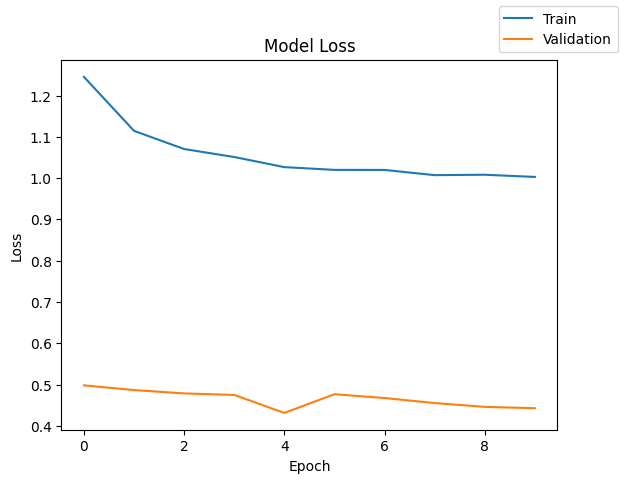

In [94]:
plot(history_2,'loss') # Visualize Loss

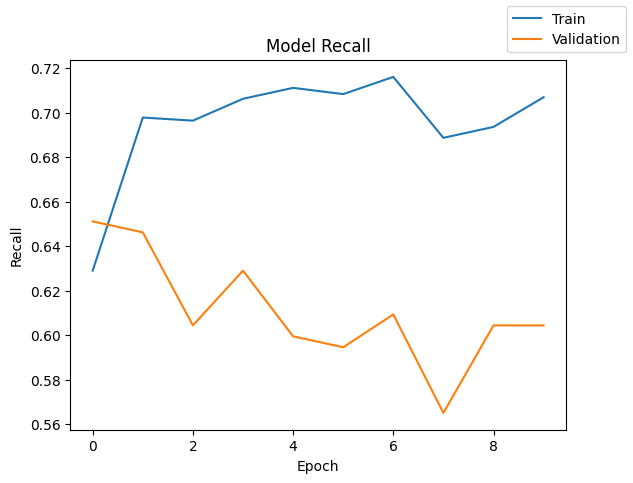

In [95]:
plot(history_2,'recall') # Visualize Recall

In [96]:
# Using pre-defined performace classifier to return metrics for training set
model_2_train_perf = model_performance_classification(model_2, X_train, y_train)
model_2_train_perf

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.823143,0.823143,0.833123,0.82736


In [97]:
# Predicting the results on the training set using 0.5 as a threshold
y_train_pred = model_2.predict(X_train)
y_train_pred = (y_train_pred > 0.42)
y_train_pred

219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[False],
       [False],
       [ True],
       ...,
       [False],
       [False],
       [False]])

In [98]:
# Using pre-defined performace classifier to return metrics for testing set
model_2_valid_perf = model_performance_classification(model_2, X_val, y_val)
model_2_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.8205,0.8205,0.826126,0.823057


In [99]:
# Predicting the results on the validation set using 0.5 as a threshold
y_val_pred = model_2.predict(X_val)
y_val_pred = (y_val_pred > 0.42)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [ True],
       [False],
       [ True]])

In [100]:
# Add model name and recall performance to the metrics list
model_name = "NN with Adam & Dropout"

train_metric_df.loc[model_name] = recall_score(y_train,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

#### Classification Report

In [101]:
# Classification report on training dataset
cr=classification_report(y_train,y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.92      0.80      0.86      5574
           1       0.49      0.73      0.58      1426

    accuracy                           0.79      7000
   macro avg       0.70      0.77      0.72      7000
weighted avg       0.83      0.79      0.80      7000



In [102]:
# Classification report on validation dataset
cr = classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.81      0.85      1593
           1       0.48      0.69      0.56       407

    accuracy                           0.78      2000
   macro avg       0.69      0.75      0.71      2000
weighted avg       0.82      0.78      0.80      2000



#### Confusion matrix

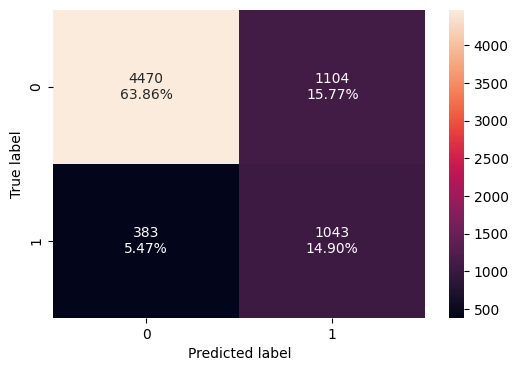

In [103]:
# Check model performance on training dataset
make_confusion_matrix(y_train, y_train_pred)

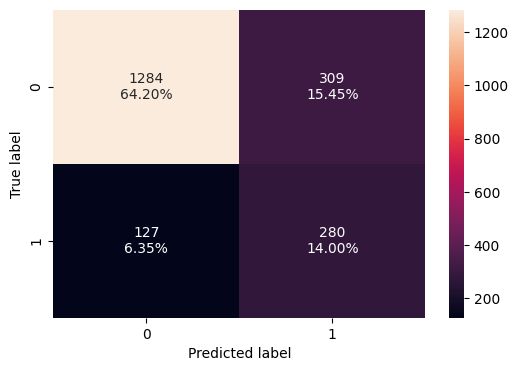

In [104]:
# Check model performance on validation dataset
make_confusion_matrix(y_val,y_val_pred)

* Looks like we've successfully handled the problem of overfitting.
* Recall and F1 Score are increased over Adam without dropout model by adding dropouts 0.4 & 0.2 for the dense hidden layers and by adjusting threshold on evaluation helped increase overall Recall and on class 1 minority class (0.69) and it's in fact pretty aligned with good precision and accuracy for this model.
* This is the best model so far in terms of performance, let's see if SMOTE sampling plays any role without class weights.

### SMOTE utility functions

In [105]:
# Pick random state for SMOTE resampler
sm  = SMOTE(random_state=42)

# Re-sample training dataset by fiting SMOTE
X_train_smote, y_train_smote= sm.fit_resample(X_train,y_train)

print('After UpSampling, the shape of train_X: {}'.format(X_train_smote.shape))
print('After UpSampling, the shape of train_y: {} \n'.format(y_train_smote.shape))

After UpSampling, the shape of train_X: (11148, 11)
After UpSampling, the shape of train_y: (11148,) 



In [106]:
# Calculate class weights for imbalanced dataset on top of SMOTE resampling
cw_smote = (y_train_smote.shape[0]) / np.bincount(y_train_smote)

# Create a dictionary mapping class indices to their respective class weights
cw_dict_smote = {}
for i in range(cw_smote.shape[0]):
    cw_dict_smote[i] = cw_smote[i]

cw_dict_smote

{0: np.float64(2.0), 1: np.float64(2.0)}

### Neural Network with Balanced Data (by applying SMOTE) and SGD Optimizer

In [107]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources
tf.keras.backend.clear_session()

In [108]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [109]:
# Initialize the neural network
model_3 = Sequential()
# Adding the input layer with 16 neurons and ReLU activation
model_3.add(Dense(16,activation='relu',input_dim = X_train_smote.shape[1]))
# Adding the input layer with 8 neurons and ReLU activation
model_3.add(Dense(8,activation='relu'))
# Adding the output layer with 1 neuron and Sigmoid activation
model_3.add(Dense(1, activation = 'sigmoid'))

In [110]:
# Let's use SGD optimizer with minimal learning rate
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)

In [111]:
# Compile the model with binary cross entropy as loss function and recall as the metric
model_3.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [112]:
model_3.summary() # Summarize the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [113]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_3 = model_3.fit(X_train_smote, y_train_smote, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping])

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6996 - recall: 0.7276 - val_loss: 0.6901 - val_recall: 0.6880
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6660 - recall: 0.6357 - val_loss: 0.6662 - val_recall: 0.6806
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6411 - recall: 0.6633 - val_loss: 0.6397 - val_recall: 0.6560
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6140 - recall: 0.6770 - val_loss: 0.6103 - val_recall: 0.6585
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5857 - recall: 0.6938 - val_loss: 0.5817 - val_recall: 0.6683
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5581 - recall: 0.7010 - val_loss: 0.5555 - val_recall: 0.6806
Epoch 7/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5322 - recall: 0.7206 - val_loss: 0.5340 - val_recall: 0.6757
Epoch 8/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5107 - recall: 0.7399 - val_loss: 0.5175 - val_recall: 0.6806
Epoch 9/

#### Analyze Loss function and Recall

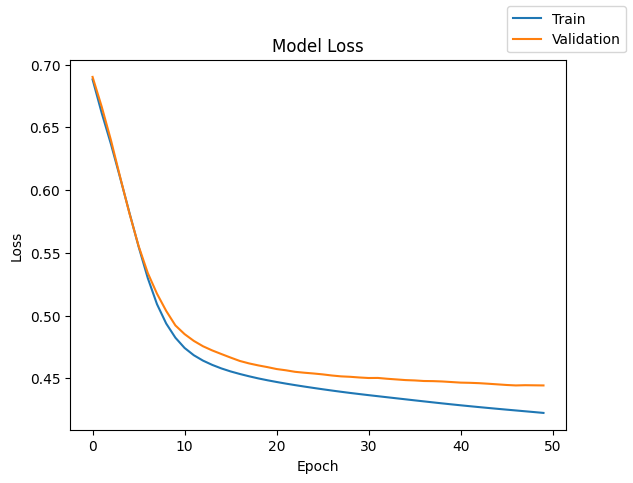

In [114]:
plot(history_3,'loss') # Visualize Loss

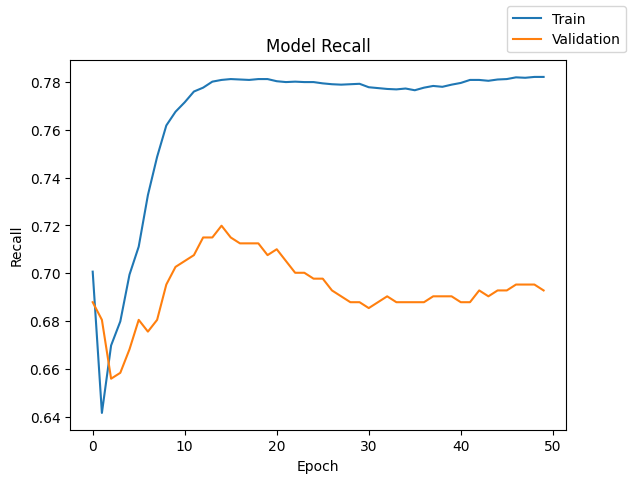

In [115]:
plot(history_3,'recall') # Visualize Recall

In [116]:
# Using pre-defined performace classifier to return metrics for training set
model_3_train_perf = model_performance_classification(model_3, X_train_smote, y_train_smote)
model_3_train_perf

349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.797363,0.797363,0.797977,0.797258


In [117]:
# Predicting the results on training set using 0.5 as the threshold
y_train_pred = model_3.predict(X_train_smote)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[False],
       [False],
       [ True],
       ...,
       [ True],
       [ True],
       [ True]])

In [118]:
# Using pre-defined performace classifier to return metrics for validation set
model_3_valid_perf = model_performance_classification(model_3, X_val, y_val)
model_3_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.793,0.793,0.82733,0.804739


In [119]:
# Predicting the results on validation set using 0.5 as the threshold
y_val_pred = model_3.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [False],
       [False],
       [ True]])

In [120]:
# Add model name and recall performance to the metrics list
model_name = "NN with SMOTE & SGD"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

#### Classification report

In [121]:
# Classification report on training dataset
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.78      0.82      0.80      5574
           1       0.81      0.77      0.79      5574

    accuracy                           0.80     11148
   macro avg       0.80      0.80      0.80     11148
weighted avg       0.80      0.80      0.80     11148



In [122]:
# Classification report on validation dataset
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.82      0.86      1593
           1       0.49      0.69      0.58       407

    accuracy                           0.79      2000
   macro avg       0.70      0.76      0.72      2000
weighted avg       0.83      0.79      0.80      2000



#### Confusion matrix

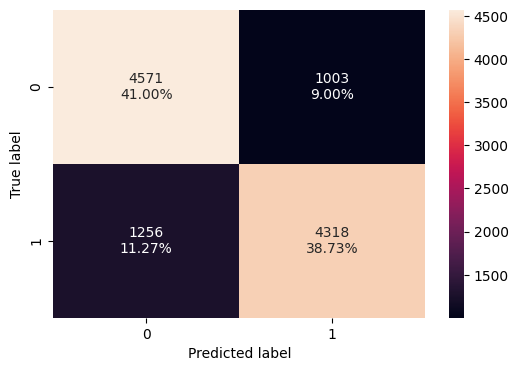

In [123]:
# Check model performance on training set
make_confusion_matrix(y_train_smote, y_train_pred)

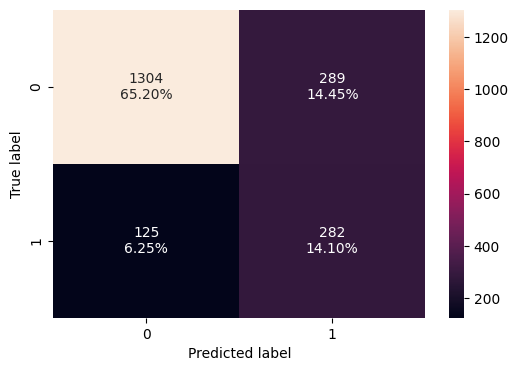

In [124]:
# Check model performance on validation set
make_confusion_matrix(y_val,y_val_pred)

* The performance has significantly gotten worse in terms of over Recall and F1 Score.
* There's a gap in the losses between training and validation test set.
* Oversampling led to overfitting with SGD optimizer.
* Let's try with Adam.

### Neural Network with Balanced Data (by applying SMOTE) and Adam Optimizer

In [125]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources
tf.keras.backend.clear_session()

In [126]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [127]:
# Initialize the neural network
model_4 = Sequential()
# Adding the input layer with 16 neurons and ReLU activation
model_4.add(Dense(16,activation='relu',input_dim = X_train_smote.shape[1]))
# Adding the input layer with 8 neurons and ReLU activation
model_4.add(Dense(8,activation='relu'))
# Adding the output layer with 1 neuron and Sigmoid activation
model_4.add(Dense(1, activation = 'sigmoid'))

In [128]:
# Let's use Adam optimizer with minimal learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

In [129]:
model_4.summary() # Summarize the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [130]:
# Compile the model with binary cross entropy as loss function and recall as the metric
model_4.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [131]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_4 = model_4.fit(X_train_smote, y_train_smote, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping])

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5504 - recall: 0.7235 - val_loss: 0.4222 - val_recall: 0.6585
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4438 - recall: 0.7600 - val_loss: 0.4397 - val_recall: 0.6708
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4311 - recall: 0.7678 - val_loss: 0.4423 - val_recall: 0.6708
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4236 - recall: 0.7706 - val_loss: 0.4381 - val_recall: 0.6658
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4169 - recall: 0.7799 - val_loss: 0.4428 - val_recall: 0.6658
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4114 - recall: 0.7824 - val_loss: 0.4533 - val_recall: 0.6658


#### Analyze Loss function and Recall

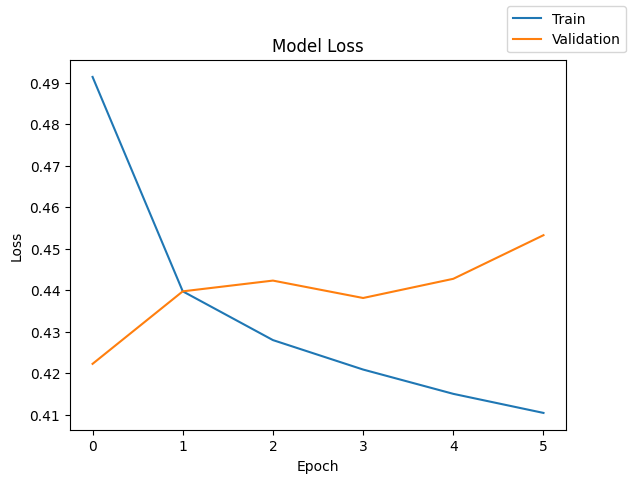

In [132]:
plot(history_4,'loss') # Visualize Loss

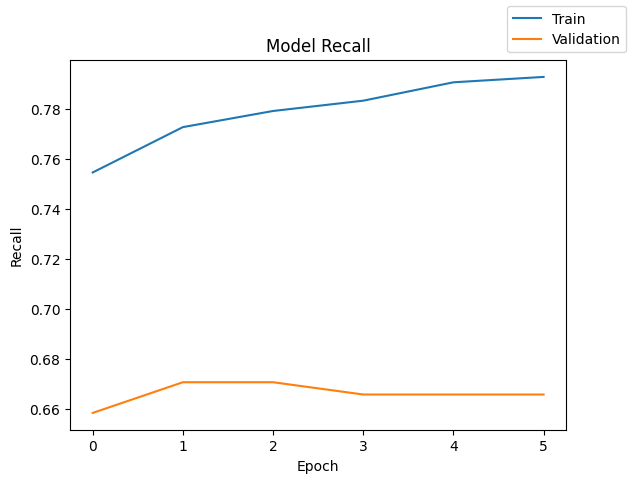

In [133]:
plot(history_4,'recall') # Visualize Recall

In [134]:
# Using pre-defined performace classifier to return metrics for training set
model_4_train_perf = model_performance_classification(model_4, X_train_smote, y_train_smote)
model_4_train_perf

349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.790097,0.790097,0.795563,0.789122


In [135]:
# Predicting the results on training set using 0.5 as the threshold
y_train_pred = model_4.predict(X_train_smote)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[False],
       [False],
       [ True],
       ...,
       [ True],
       [ True],
       [False]])

In [136]:
# Using pre-defined performace classifier to return metrics for validation set
model_4_valid_perf = model_performance_classification(model_4, X_val, y_val)
model_4_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.817,0.817,0.833114,0.823328


In [137]:
# Predicting the results on validation set using 0.5 as the threshold
y_val_pred = model_4.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [False],
       [False],
       [ True]])

In [138]:
# Add model name and recall performance to the metrics list
model_name = "NN with SMOTE & Adam"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

#### Classification Report

In [139]:
# Classification report on training dataset
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.76      0.86      0.80      5574
           1       0.84      0.72      0.77      5574

    accuracy                           0.79     11148
   macro avg       0.80      0.79      0.79     11148
weighted avg       0.80      0.79      0.79     11148



In [140]:
## Classification report on validation dataset
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.86      0.88      1593
           1       0.54      0.66      0.59       407

    accuracy                           0.82      2000
   macro avg       0.72      0.76      0.74      2000
weighted avg       0.83      0.82      0.82      2000



#### Confusion matrix

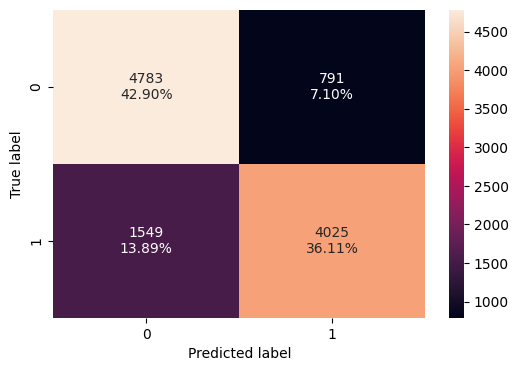

In [141]:
# Check model performance on training set
make_confusion_matrix(y_train_smote, y_train_pred)

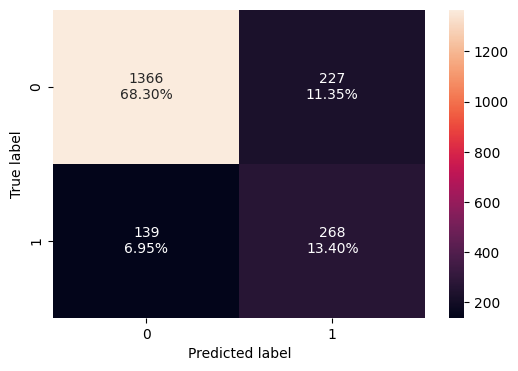

In [142]:
# Check model performance on training set
make_confusion_matrix(y_val,y_val_pred)

* There's no major improvement in the performace using Adam optimizer.
* In fact it's performing too well on validation set leading to underfitting due to imbalance assignment by SMOTE.
* Since the last best performance was with Adam & Dropout, let's try using SMOTE with it.

### Neural Network with Balanced Data (by applying SMOTE), Adam Optimizer, and Dropout

In [143]:
# Clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources
tf.keras.backend.clear_session()

In [144]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [145]:
# Initialize the neural network
model_5 = Sequential()
# Adding the input layer with 16 neurons and ReLU activation
model_5.add(Dense(16,activation='relu',input_dim = X_train_smote.shape[1]))
# Adding dropout to the hidden layer
model_5.add(Dropout(0.2))
# Adding dropout to the hidden layer
model_5.add(Dense(8,activation='relu'))
# Adding the input layer with 16 neurons and ReLU activation
model_5.add(Dropout(0.2))

# Adding the output layer with 1 neuron and Sigmoid activation
model_5.add(Dense(1, activation = 'sigmoid'))

In [146]:
# Let's use Adam optimizer with minimal learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

In [147]:
# Compile the model with binary cross entropy as loss function and recall as the metric
model_5.compile(loss='binary_crossentropy',optimizer=optimizer,metrics=[metric])

In [148]:
model_5.summary() # Summarize the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [149]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history_5 = model_5.fit(X_train_smote, y_train_smote, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping])

Epoch 1/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5993 - recall: 0.6645 - val_loss: 0.4869 - val_recall: 0.7125
Epoch 2/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4924 - recall: 0.7272 - val_loss: 0.4671 - val_recall: 0.6511
Epoch 3/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4816 - recall: 0.7274 - val_loss: 0.4759 - val_recall: 0.7027
Epoch 4/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4716 - recall: 0.7312 - val_loss: 0.4631 - val_recall: 0.6781
Epoch 5/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4724 - recall: 0.7414 - val_loss: 0.4850 - val_recall: 0.6953
Epoch 6/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4691 - recall: 0.7355 - val_loss: 0.4481 - val_recall: 0.6462
Epoch 7/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4671 - recall: 0.7384 - val_loss: 0.4776 - val_recall: 0.7150
Epoch 8/50
349/349 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4565 - recall: 0.7477 - val_loss: 0.4571 - val_recall: 0.6880
Epoch 9/

#### Analyze Loss function and Recall

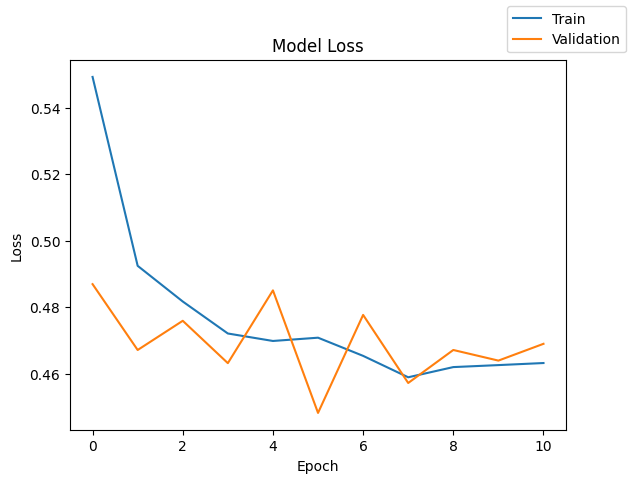

In [150]:
plot(history_5,'loss') # Visualize Loss

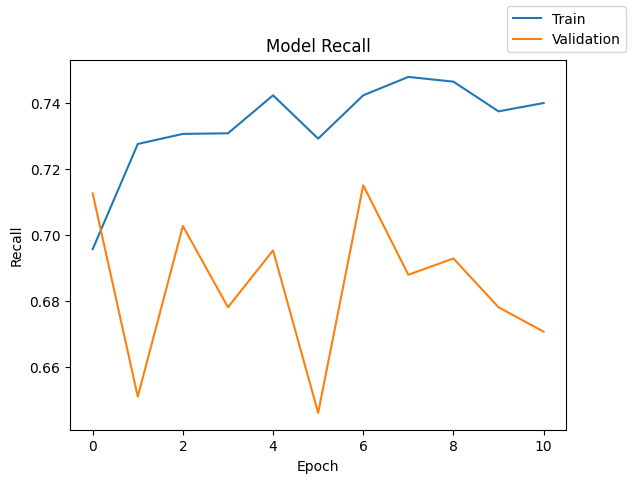

In [151]:
plot(history_5,'recall') # Visualize Recall

In [152]:
# Using pre-defined performace classifier to return metrics for training set
model_5_train_perf = model_performance_classification(model_5, X_train_smote, y_train_smote)
model_5_train_perf

349/349 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.790545,0.790545,0.795188,0.789719


In [153]:
# Predicting the results on training set using 0.5 as the threshold
y_train_pred = model_5.predict(X_train_smote)
y_train_pred = (y_train_pred > 0.5)
y_train_pred

349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[False],
       [False],
       [ True],
       ...,
       [ True],
       [ True],
       [ True]])

In [154]:
# Using pre-defined performace classifier to return metrics for validation set
model_5_valid_perf = model_performance_classification(model_5, X_val, y_val)
model_5_valid_perf

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.8135,0.8135,0.829223,0.819761


In [155]:
# Predicting the results on validation set using 0.5 as the threshold
y_val_pred = model_5.predict(X_val)
y_val_pred = (y_val_pred > 0.5)
y_val_pred

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[ True],
       [False],
       [False],
       ...,
       [False],
       [False],
       [ True]])

In [156]:
# Add model name and recall performance to the metrics list
model_name = "NN with SMOTE,Adam & Dropout"

train_metric_df.loc[model_name] = recall_score(y_train_smote,y_train_pred)
valid_metric_df.loc[model_name] = recall_score(y_val,y_val_pred)

#### Classification Report

In [157]:
# Classification report on training dataset
cr=classification_report(y_train_smote,y_train_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.76      0.85      0.80      5574
           1       0.83      0.73      0.78      5574

    accuracy                           0.79     11148
   macro avg       0.80      0.79      0.79     11148
weighted avg       0.80      0.79      0.79     11148



In [158]:
# Classification report on validation dataset
cr=classification_report(y_val,y_val_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1593
           1       0.53      0.65      0.59       407

    accuracy                           0.81      2000
   macro avg       0.72      0.75      0.73      2000
weighted avg       0.83      0.81      0.82      2000



#### Confusion matrix

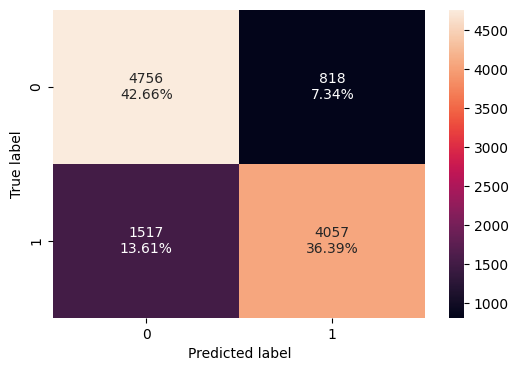

In [159]:
# Check model performance on training set
make_confusion_matrix(y_train_smote, y_train_pred)

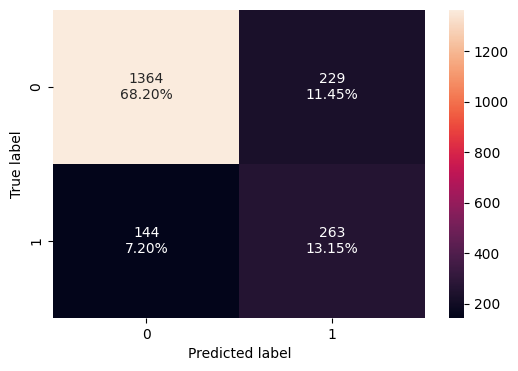

In [160]:
# Check model performance on validation set
make_confusion_matrix(y_val,y_val_pred)

* Even without class weights, this model is learning too well on validation set, so the performance of training data is lower than validation set.
* No improvement on previous SMOTE models.

## Model Performance Comparison and Final Model Selection

#### Comparision function results

In [161]:
# Training performance comparison
models_train_comp_df = pd.concat(
    [
        model_0_train_perf.T,
        model_1_train_perf.T,
        model_2_train_perf.T,
        model_3_train_perf.T,
        model_4_train_perf.T,
        model_5_train_perf.T
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4, 0.2])",
    "Neural Network (SGD, SMOTE)",
    "Neural Network (Adam, SMOTE)",
    "Neural Network (Adam, dropout, SMOTE)"
]

In [162]:
#Validation performance comparison

models_valid_comp_df = pd.concat(
    [
        model_0_valid_perf.T,
        model_1_valid_perf.T,
        model_2_valid_perf.T,
        model_3_valid_perf.T,
        model_4_valid_perf.T,
        model_5_valid_perf.T
    ],
    axis=1,
)
models_valid_comp_df.columns = [
    "Neural Network (SGD, No Regularization)",
    "Neural Network (Adam , No Regularization)",
    "Neural Network (Adam, dropout [0.4, 0.2])",
    "Neural Network (SGD, SMOTE)",
    "Neural Network (Adam, SMOTE)",
    "Neural Network (Adam, dropout, SMOTE)"
]

In [163]:
models_train_comp_df # Display the training set comparision chart

,"Neural Network (SGD, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4, 0.2])","Neural Network (SGD, SMOTE)","Neural Network (Adam, SMOTE)","Neural Network (Adam, dropout, SMOTE)"
Accuracy,0.764000,0.829571,0.823143,0.797363,0.790097,0.790545
Recall,0.764000,0.829571,0.823143,0.797363,0.790097,0.790545
Precision,0.816162,0.850292,0.833123,0.797977,0.795563,0.795188
F1 Score,0.780622,0.836926,0.827360,0.797258,0.789122,0.789719


In [164]:
models_valid_comp_df # Display validation set comparision chart

,"Neural Network (SGD, No Regularization)","Neural Network (Adam , No Regularization)","Neural Network (Adam, dropout [0.4, 0.2])","Neural Network (SGD, SMOTE)","Neural Network (Adam, SMOTE)","Neural Network (Adam, dropout, SMOTE)"
Accuracy,0.774000,0.812000,0.820500,0.793000,0.817000,0.813500
Recall,0.774000,0.812000,0.820500,0.793000,0.817000,0.813500
Precision,0.820146,0.831261,0.826126,0.827330,0.833114,0.829223
F1 Score,0.789010,0.819358,0.823057,0.804739,0.823328,0.819761


In [165]:
models_train_comp_df.loc["Recall"] - models_valid_comp_df.loc["Recall"] # Show the difference between both Training and validation Recall

,Recall
"Neural Network (SGD, No Regularization)",-0.010000
"Neural Network (Adam , No Regularization)",0.017571
"Neural Network (Adam, dropout [0.4, 0.2])",0.002643
"Neural Network (SGD, SMOTE)",0.004363
"Neural Network (Adam, SMOTE)",-0.026903
"Neural Network (Adam, dropout, SMOTE)",-0.022955


In [166]:
# Overall metrics performance on test dataset
model_t = model_performance_classification(model_2, X_test, y_test)
model_t

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.814,0.814,0.827877,0.81965


* The final and the best model is inevitably Neural **Network (Adam, dropout [0.4, 0.2])**
* Model_2 or Adam with dropout has the best recall and it's consistent with the training dataset.
* Even the Precision and F1 Score is the best possible among all other models.
* When considering validation scores only, Model 6 outperforms others, suggesting its effectiveness in real-world applications and new data scenarios.

#### Library Metric Comparision Report results

In [167]:
# Print Train metric comparison list
print("Training performance comparison")
train_metric_df

Training performance comparison


,recall
NN with SGD,0.698457
NN with Adam,0.723001
NN with Adam & Dropout,0.731417
NN with SMOTE & SGD,0.774668
NN with SMOTE & Adam,0.722103
"NN with SMOTE,Adam & Dropout",0.727844


In [168]:
# Print Validation metric comparison list
print("Validation set performance comparison")
valid_metric_df

Validation set performance comparison


,recall
NN with SGD,0.697789
NN with Adam,0.663391
NN with Adam & Dropout,0.687961
NN with SMOTE & SGD,0.692875
NN with SMOTE & Adam,0.658477
"NN with SMOTE,Adam & Dropout",0.646192


In [169]:
train_metric_df - valid_metric_df # Difference in recall from both the trainig and validation sets

,recall
NN with SGD,0.000669
NN with Adam,0.059611
NN with Adam & Dropout,0.043456
NN with SMOTE & SGD,0.081793
NN with SMOTE & Adam,0.063626
"NN with SMOTE,Adam & Dropout",0.081652


* NN with Adam & Dropout has the least difference in Recall between training and validation datasets, indicating not much overfitting or underfitting but a good balance.
* Additionally it has the best recall score in validation set.
* Adam optimizer definitely outperforms SGD for this dataset.
* So, model_2 or NN with Adam & Dropout(0.4,0.2) seems like the best choice to perform evaluations on the test data.

#### Predict the best model on Test dataset

In [170]:
# Predict on test dataset
y_test_pred = model_2.predict(X_test)
y_test_pred = (y_test_pred > 0.42)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [171]:
# Get classification report on test dataset
cr=classification_report(y_test,y_test_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.92      0.79      0.85       796
           1       0.47      0.72      0.57       204

    accuracy                           0.78      1000
   macro avg       0.69      0.76      0.71      1000
weighted avg       0.83      0.78      0.79      1000



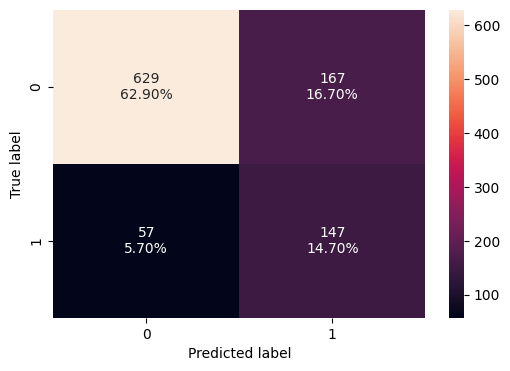

In [172]:
# Check model performance on test dataset
make_confusion_matrix(y_test,y_test_pred)

* This model can predict 72% of class 1 insstances correctly out of 204 which is approx 147 customers out of 204 who will actually leave the bank in 6 months.
* Seems pretty good number considering the imbalanced dataset.
* The 0.42 threshold improves the Class 1 F1-Score slightly and maintains it.
The model has a decent overall accuracy (78%) but shows imbalance in performance between classes, with better prediction for Class 0.
* The low precision for Class 1 (0.47) suggests many false positives, while the higher recall (0.72) indicates it captures most Class 1 instances but with good confidence.
* The confusion matrix highlights a tendency to over-predict Class 1 for Class 0 instances, which could be due to an imbalanced dataset or threshold tuning issues. Model can be improved by adjusting class weights or the threshold further, but this performs the best on test set.

### Final Model - Adam with dropout [0.4, 0.2]

In [221]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [222]:
# Fixing the seed for random number generators so that we can ensure we receive the same output everytime
np.random.seed(2)
random.seed(2)
tf.random.set_seed(2)

In [223]:
# Initializing the neural network
model = Sequential()

# Adding the input layer with 16 neurons and ReLU activation
model.add(Dense(16,activation='relu',input_dim = X_train.shape[1]))
# Add dropout rate
model.add(Dropout(0.4))
# Adding the input layer with 8 neurons and ReLU activation
model.add(Dense(8,activation='relu'))
# Add dropout rate
model.add(Dropout(0.2))

# Adding the output layer with one neuron Sigmmoid activation
model.add(Dense(1, activation = 'sigmoid'))

In [224]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [225]:
optimizer = tf.keras.optimizers.Adam()    # Defining Adam as the optimizer to be used
model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=[metric])

In [226]:
# Train with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit model with helping functions
history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=cw_dict)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.4961 - recall: 0.6788 - val_loss: 0.6450 - val_recall: 0.5823
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.3443 - recall: 0.5811 - val_loss: 0.6141 - val_recall: 0.5774
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.2680 - recall: 0.5889 - val_loss: 0.5905 - val_recall: 0.6093
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.2341 - recall: 0.6100 - val_loss: 0.5659 - val_recall: 0.6044
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.1927 - recall: 0.6356 - val_loss: 0.5432 - val_recall: 0.6314
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1283 - recall: 0.6812 - val_loss: 0.5288 - val_recall: 0.6388
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1273 - recall: 0.6608 - val_loss: 0.5142 - val_recall: 0.6634
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.1229 - recall: 0.6743 - val_loss: 0.5066 - val_recall: 0.6732
Epoch 9/

In [227]:
# Predicting model on all three datasets
y_train_pred = model.predict(X_train)
y_valid_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [228]:
print("Classification Report - Train data",end="\n\n")
cr = classification_report(y_train,y_train_pred>0.42)
print(cr)

Classification Report - Train data

              precision    recall  f1-score   support

           0       0.94      0.73      0.82      5574
           1       0.43      0.81      0.57      1426

    accuracy                           0.75      7000
   macro avg       0.69      0.77      0.69      7000
weighted avg       0.84      0.75      0.77      7000



In [229]:
print("Classification Report - Validation data",end="\n\n")
cr = classification_report(y_val,y_val_pred>0.42)
print(cr)

Classification Report - Validation data

              precision    recall  f1-score   support

           0       0.90      0.86      0.88      1593
           1       0.53      0.65      0.59       407

    accuracy                           0.81      2000
   macro avg       0.72      0.75      0.73      2000
weighted avg       0.83      0.81      0.82      2000



In [230]:
print("Classification Report - Test data",end="\n\n")
cr = classification_report(y_test,y_test_pred>0.42)
print(cr)

Classification Report - Test data

              precision    recall  f1-score   support

           0       0.93      0.71      0.81       796
           1       0.41      0.79      0.54       204

    accuracy                           0.73      1000
   macro avg       0.67      0.75      0.68      1000
weighted avg       0.82      0.73      0.75      1000



* Test data evaluations on the picked Adam with dropout model are consistent with our previous classification report and confusion matrix analysis.
* Accuracy is 0.77 which is well aligned with training dataset.
* It performs well on test dataset.

## Business Insights and Recommendations

* Bank can deploy the final model as trained above to identify with a reasonable degree of accuracy whether a customer will leave/churn the bank in next 6 months, and this method seems to be more effective & time-efficent than the others.

* The bank should prioritize various incentive programs to keep their customers like launch a re-engagement campaign offering incentives (e.g., 2% interest bonus on savings or fee waivers) to inactive customers since customers with IsActiveMember=0 are more likely to churn. Contact them via email or SMS within 30 days of inactivity, tracking response rates to refine offers.

* Age is strongly related to the Exited or Churn dependent variable. Focus on people with older ages (eg; 59, 66, etc.) since they are more likely to churn.

* Introduce low-balance alerts with personalized advice (e.g., “Add $500 to earn 1.5% interest”) or micro-investment options (e.g., $50 stock plans) to encourage activity. Pilot this with the bottom 20% of balance holders (e.g., < $10,000) bc Balance is still weak but positively related to Exited.

* Just like Balance, NumOfPrroducts is strongly related to Exited as well and it has impact on the decision like customers with NumOfProducts = 1 (e.g., rows 2, 5) show higher churn rates. Offer bundled products (e.g., savings + credit card) with a 10% discount for customers with one product, and tailored retirement plans for customers over 50 to meet their needs, reducing churn by appealing to their lifecycle stage.

* Customize offerings by region—e.g., higher interest rates in Germany, or gender-specific perks (e.g., women’s financial workshops) based on Gender. Test these with a 500-customer pilot per region to gauge effectiveness.

* Implement a loyalty program with rewards (e.g., $50 cashback) for customers reaching 1, 3, and 5 years, encouraging longer stays. Focus on new customers (Tenure < 2) with welcome calls within the first month.

* Offer bundled products (e.g., savings + credit card) with a 10% discount for customers with one product, and tailored retirement plans for customers over 50 to meet their needs, reducing churn by appealing to their lifecycle stage.

* One can tweak the employed techniques like oversampling minority classes, using appropriate evaluation metrics (e.g., Recall), or employing ensemble methods like SMOTE (Synthetic Minority Over-sampling Technique) to address class imbalance by increasing model complexity or set density/hidden layers and adjust learning rate to balance. Additionally one can add class weight while fitting on trained SMOTE.
Another way of experimenting is adjusting dropout values depending on the prior performance. Threshold adjustments could be really useful too while evaluating the performance.
Ensuring a balanced dataset is crucial for model training to avoid biased predictions.



## <a name='link1'>Appendix: Detailed Exploratory Data Analysis (EDA)</a>

### Univariate Analysis

#### CreditScore

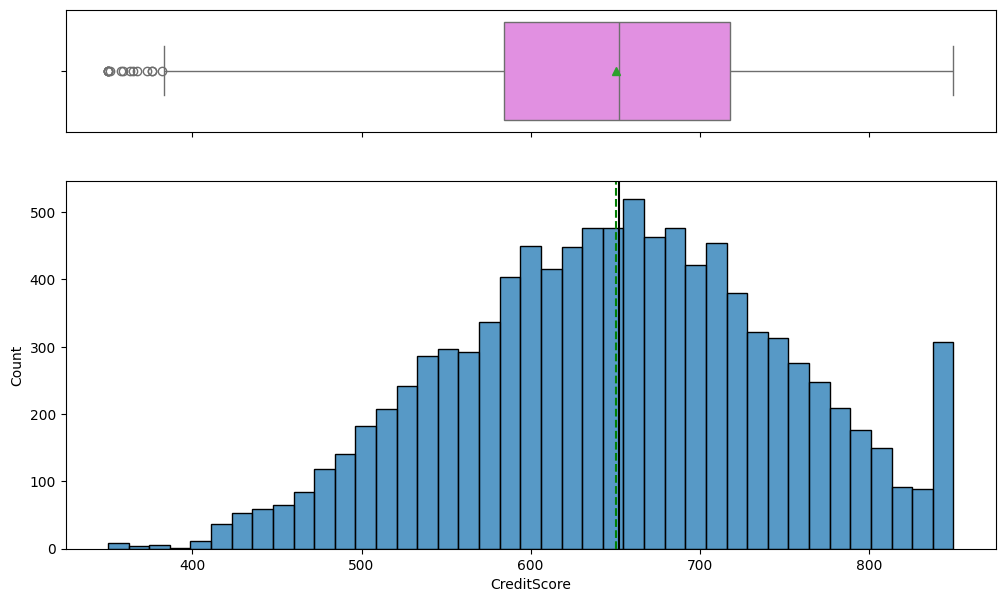

In [182]:
histogram_boxplot(df,'CreditScore')

* Roughly symmetric, slightly left-skewed, with a peak around 650. Outliers exist at the low end (~350) and a spike at 850.
* Low scores (~350) are outliers (circles in box plot), and there’s a notable spike at 850.
* CreditScore is mostly normal, centered around 650, with 50% of values between 584 and 718. The outliers and spike suggest some customers have exceptionally low or perfect scores.

#### Age

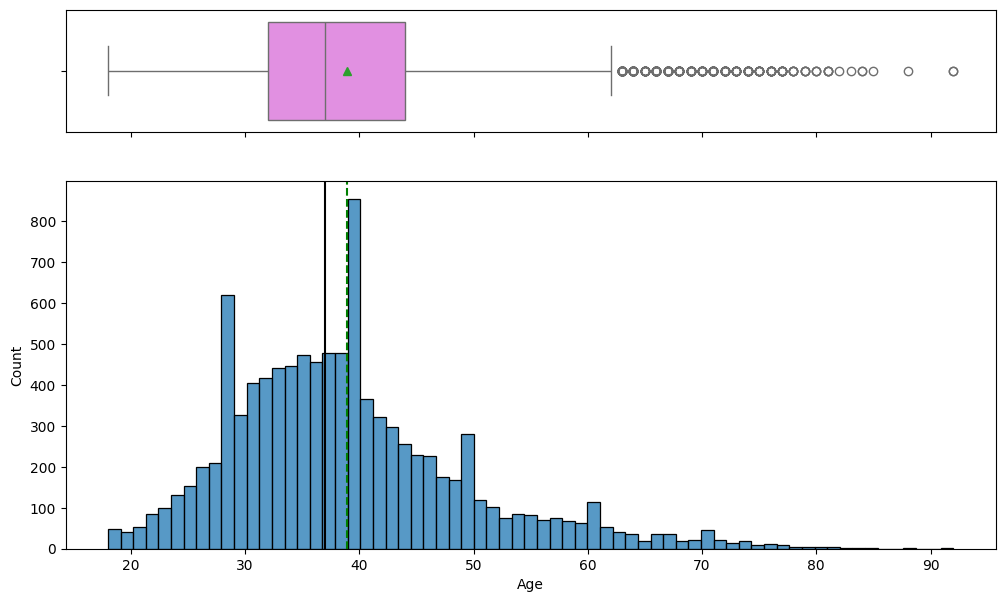

In [183]:
histogram_boxplot(df, 'Age')

* Age is right-skewed, ranging from 18 to 92 (mean = 38.92, median = 37), with most customers (50%) between 32 and 44. Older customers (50+) are less frequent but present as outliers.
* Older customers are more likely to churn, with a mean age of 44.84 for churned vs. 37.52 for stayed. Churn rates increase with age: 33.3% for 18–30, 18.75% for 30–50, and 41.7% for 50+.
* Age is a significant predictor of churn, with older customers at higher risk. Retention strategies should target customers over 50, possibly addressing issues like retirement needs or dissatisfaction.

#### Tenure

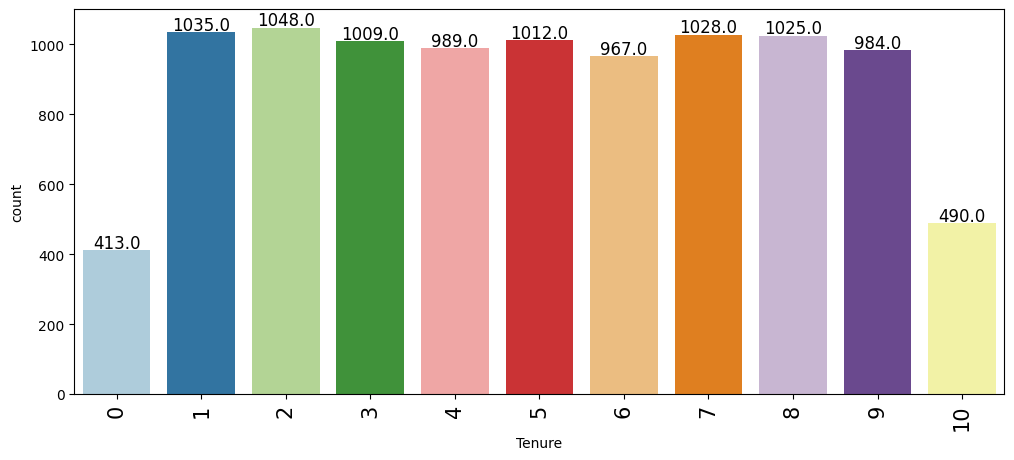

In [184]:
labeled_barplot(df, 'Tenure')

* Tenure is uniformly distributed from 0 to 10 years (mean = 5.01, median = 5), with 50% of customers having tenures between 3 and 7 years. There are no outliers due to the capped range.
* Shorter-tenured customers (0–3 years) have a higher churn rate (22.3%), while longer-tenured customers (4–10 years) have lower rates (19.4%–19.6%). The mean tenure is 5.09 years for stayed vs. 4.70 years for churned.
* Tenure is a relevant predictor of churn, with newer customers at higher risk. Retention strategies should focus on customers with tenures of 0–3 years, possibly addressing early dissatisfaction or onboarding issues.

#### Balance

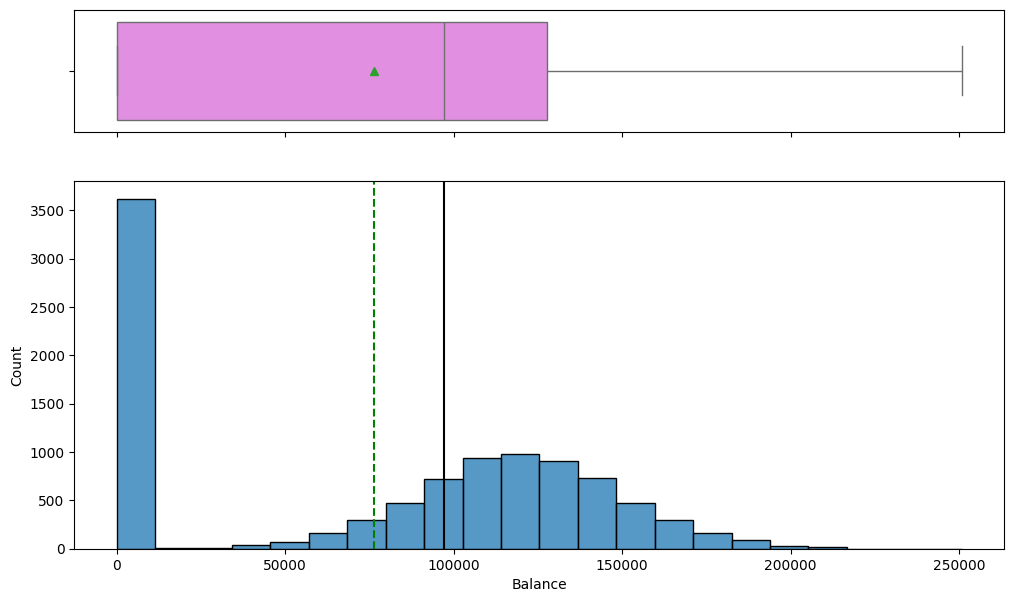

In [185]:
histogram_boxplot(df, 'Balance')

* Balance ranges from 0 to 250,898.09 (mean = 76,485.89, median = 97,198.54) and is heavily right-skewed. 36.31% of customers have a zero balance, and the middle 50% of non-zero balances are between 97,198.54 and 127,644.24. High variability (std = 62,397.41) indicates diverse account activity.
* The large proportion of zero balances suggests many inactive or new accounts, while the right skew and high max reflect a smaller group of high-value accounts. This distribution may impact analyses involving financial activity, such as churn prediction.

#### NumOfProducts

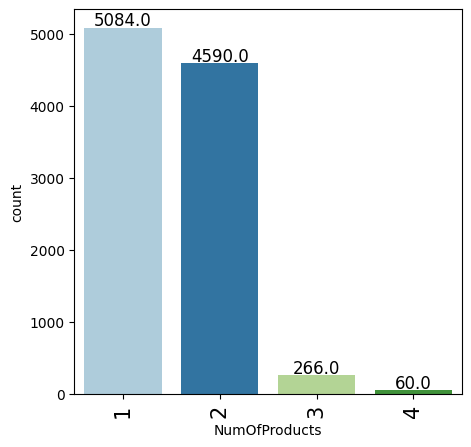

In [186]:
labeled_barplot(df, 'NumOfProducts')

* NumOfProducts ranges from 1 to 4 (mean = 1.53, median = 1) and is heavily right-skewed. 96.76% of customers have 1 or 2 products (50.86% with 1, 45.90% with 2), while 3 and 4 products are rare (2.64% with 3, 0.60% with 4). Customers with 4 products are outliers.
* The majority of customers have 1 or 2 products, with very few having more, indicating limited product engagement for most. The right-skewed distribution and small variability (std = 0.58) suggest a customer base with low product diversity.

#### IsActiveMember

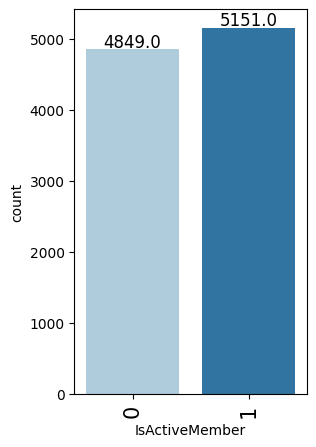

In [187]:
labeled_barplot(df, 'IsActiveMember')

* IsActiveMember is a binary variable with 51.51% of customers being active (5,151) and 48.49% inactive (4,849). The mean (0.5151) and median (1) indicate a slight majority of active members, with a standard deviation of 0.4998 reflecting a balanced distribution.
* The near 50/50 split suggests a customer base that is fairly evenly divided between active and inactive members, with a slight lean toward activity. This balance may be relevant for strategies aimed at increasing engagement among inactive members.

#### HasCrCard

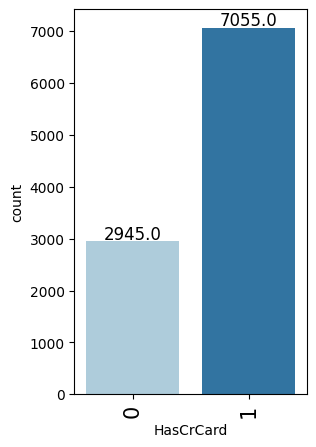

In [188]:
labeled_barplot(df, 'HasCrCard')

* HasCrCard is a binary variable with 70.55% of customers having a credit card (7,055) and 29.45% not having one (2,945). The mean (0.7055) and median (1) indicate a majority with credit cards, with a standard deviation of 0.4558 reflecting the 70/30 split.
* The majority of customers (70.55%) have a credit card, suggesting widespread credit card usage in this customer base. The 2.4:1 ratio of credit card holders to non-holders may be relevant for strategies targeting credit card engagement or acquisition.

#### EstimatedSalary

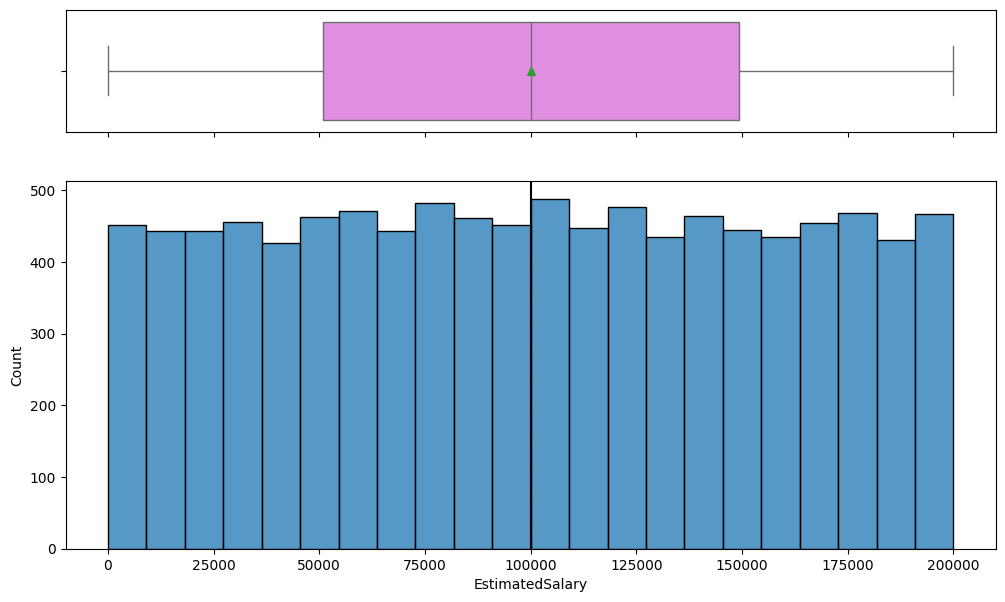

In [189]:
histogram_boxplot(df, 'EstimatedSalary')

* EstimatedSalary ranges from 11.58 to 199,992.48 (mean ≈ 100,099.17, median ≈ 100,090.24) and is roughly uniform with peaks at the extremes (near 0 and 200,000). The middle 50% of salaries are between 51,074.32 and 149,388.88, with no outliers.
* The uniform distribution with peaks at the low and high ends indicates a diverse customer base in terms of income. The extreme values (11.58 and peaks near 0/200,000) may suggest data artifacts or rounding, and the symmetry (mean ≈ median) is notable despite the shape.

#### Gender

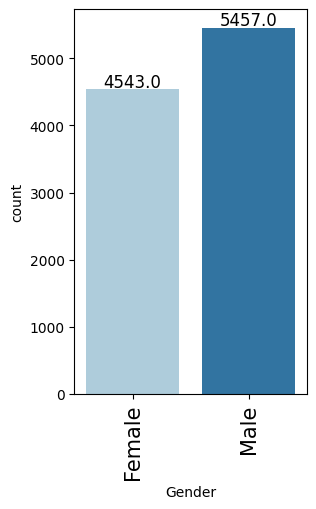

In [190]:
labeled_barplot(df, 'Gender')

* Gender is a binary categorical variable with 54.57% Male (5,457 customers) and 45.43% Female (4,543 customers). The distribution is fairly balanced but slightly skewed toward males.
* The slight male majority (54.57%) indicates a modest gender imbalance in the customer base, with both genders well-represented but males being more common by a 1.2:1 ratio.

#### Geography

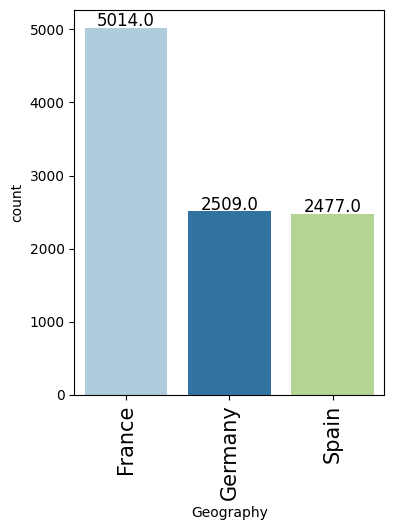

In [191]:
labeled_barplot(df, 'Geography')

* Geography is a categorical variable with three levels: France (50.14%, 5,014 customers), Germany (25.09%, 2,509 customers), and Spain (24.77%, 2,477 customers). France dominates with half the customers, while Germany and Spain are nearly equal.
* The distribution is skewed toward France (50.14%), with a 2:1 ratio compared to Germany or Spain, which are balanced with each other. This imbalance may reflect the bank’s market focus or data sampling, and could influence analyses involving regional factors.

#### Exited

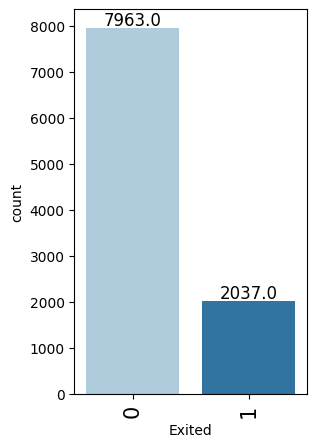

In [192]:
labeled_barplot(df, 'Exited')

* Exited is a binary variable with 79.63% of customers staying (7,963) and 20.37% churning (2,037). The mean (0.2037) and median (0) indicate a strong majority of non-churners, with a standard deviation of 0.4028 reflecting the 80/20 split.
* The 20.37% churn rate and 4:1 ratio of non-churners to churners suggest a stable customer base with a minority of churners, potentially warranting focused retention strategies for the churned group.

### Bivariate Analysis

#### Geography and Exited

Exited        0     1    All
Geography                   
All        7963  2037  10000
Germany    1695   814   2509
France     4204   810   5014
Spain      2064   413   2477
------------------------------------------------------------------------------------------------------------------------


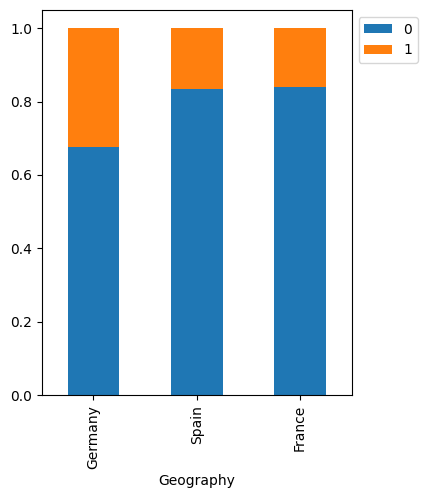

In [193]:
stacked_barplot(df, "Geography", "Exited" )

* Geography has a strong association with Exited. Germany has a significantly higher churn rate (32.44%) compared to France (16.24%) and Spain (16.51%), which are similar to each other.
* German customers are at a much higher risk of churning, with a rate 1.6x the overall average, suggesting regional factors influencing churn behavior.
* The bank should prioritize retention efforts in Germany, potentially investigating local market conditions, competition, or customer satisfaction issues specific to that region.

#### Gender and Exited

Exited     0     1    All
Gender                   
All     7963  2037  10000
Female  3404  1139   4543
Male    4559   898   5457
------------------------------------------------------------------------------------------------------------------------


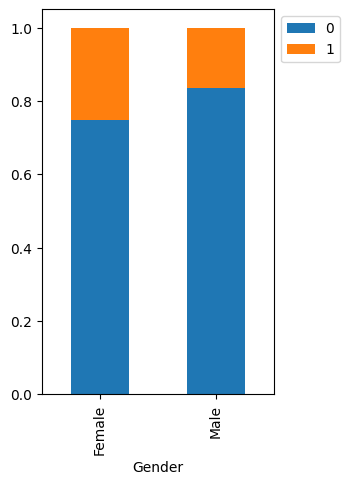

In [194]:
stacked_barplot(df, "Gender", "Exited" )

* Gender has a moderate association with Exited. Female customers have a higher churn rate (24.39%) compared to male customers (17.02%), a difference of 7.37%.
Key Insight: Females are about 43% more likely to churn than males, indicating that gender plays a role in churn behavior.
* The bank should focus retention efforts on female customers, potentially exploring gender-specific factors like product preferences, customer service experiences, or financial needs that may contribute to higher churn rates.

#### IsActiveMember and Exited

Exited             0     1    All
IsActiveMember                   
All             7963  2037  10000
0               3547  1302   4849
1               4416   735   5151
------------------------------------------------------------------------------------------------------------------------


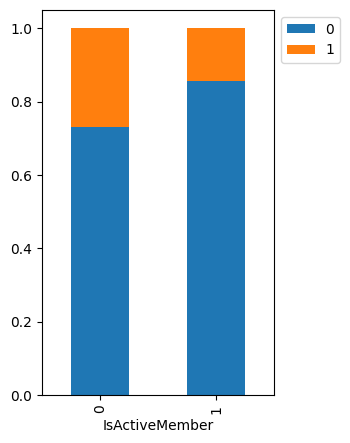

In [195]:
stacked_barplot(df, "IsActiveMember", "Exited" )

* IsActiveMember has a strong negative association with Exited. Inactive members have a higher churn rate (26.87%) compared to active members (14.25%), a difference of 12.62%.
* Inactive members are 89% more likely to churn than active members, indicating that engagement status is a key predictor of churn.
* The bank should focus on re-engaging inactive members through targeted campaigns, incentives, or improved services to boost activity levels and reduce churn risk.

#### HasCreditCard and Exited

Exited        0     1    All
HasCrCard                   
All        7963  2037  10000
1          5631  1424   7055
0          2332   613   2945
------------------------------------------------------------------------------------------------------------------------


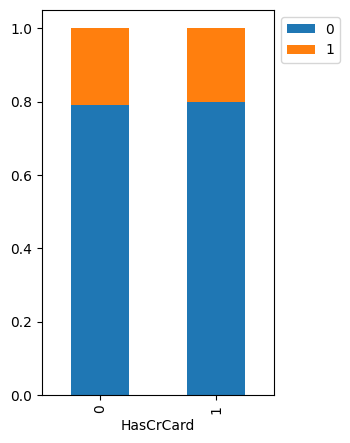

In [196]:
stacked_barplot(df, "HasCrCard", "Exited" )

* HasCrCard has a very weak association with Exited. Customers without a credit card have a slightly higher churn rate (20.85%) compared to those with a credit card (20.17%), a difference of only 0.68%.
* Credit card ownership has negligible impact on churn behavior, with churn rates in both groups close to the overall average (20.37%).
* Retention strategies should not prioritize credit card ownership, as it doesn’t significantly influence churn. Instead, focus on stronger predictors like engagement (IsActiveMember) or number of products.

#### CreditScore and Exited

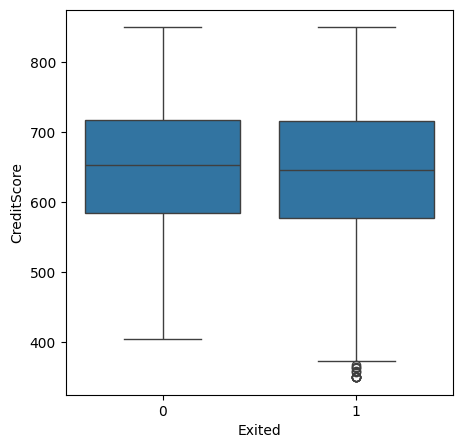

In [197]:
plt.figure(figsize=(5,5))
sns.boxplot(y='CreditScore',x='Exited',data=df)
plt.show()

* CreditScore has a moderate negative association with Exited. Customers who churned have a lower average CreditScore (639.53) compared to those who stayed (653.32), with churn rates higher for low scores (33% for <450) and lower for high scores (16.5% at 850).
* Lower credit scores are linked to increased churn risk, possibly due to financial instability or dissatisfaction, while higher scores correlate with retention.
* he bank should target customers with lower credit scores (<450) for retention efforts, potentially offering financial education, support programs, or incentives to improve their scores and reduce churn risk.

#### Age and Exited

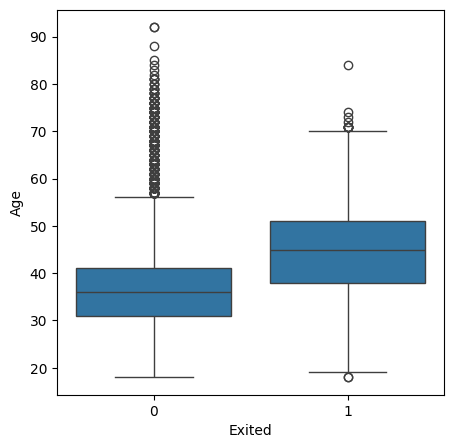

In [198]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Age',x='Exited',data=df)
plt.show()

* Age has a strong positive association with Exited. Churned customers are older on average (44.84 years) than those who stayed (37.52 years), with churn rates increasing with age (41.7% for 50+ vs. 18.75% for 30–50).
* Older customers, particularly those aged 38–67, are at higher risk of churning, likely due to life stage changes or unmet needs.
* The bank should prioritize retention strategies for older customers (e.g., 38–67 years), offering services tailored to their life stages, such as retirement planning or enhanced customer support, to reduce churn risk.

#### Tenure and Exited

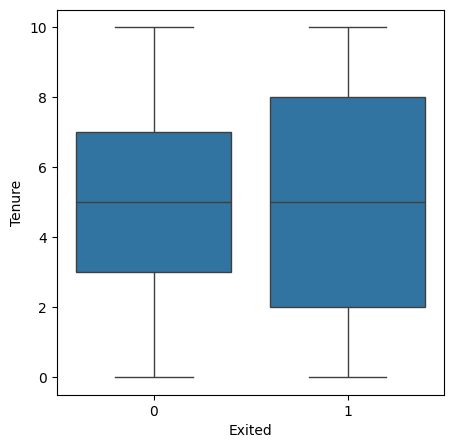

In [199]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Tenure',x='Exited',data=df)
plt.show()

* Tenure has a weak negative association with Exited. Churned customers have a slightly shorter average tenure (4.70 years) compared to those who stayed (5.09 years), with higher churn rates for shorter tenures (22.3% for 0–3 years vs. 19.4%–19.6% for 4–10 years).
* Newer customers (0–3 years) are slightly more likely to churn, possibly due to early dissatisfaction or lack of loyalty, though the effect is modest.
* The bank should enhance onboarding and early engagement strategies for customers with tenures of 0–3 years, offering incentives or improved support to build loyalty and reduce churn risk during this period.

#### Balance and Exited

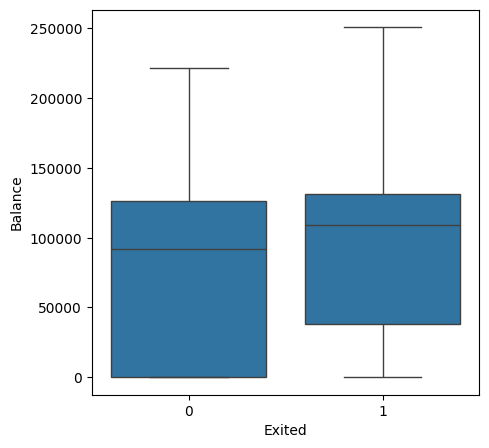

In [200]:
plt.figure(figsize=(5,5))
sns.boxplot(y='Balance',x='Exited',data=df)
plt.show()

* Balance has a moderate positive association with Exited. Churned customers have a higher average balance (91,108.96) compared to those who stayed (72,761.29), with churn rates increasing with balance (26.5% for 100K+ vs. 14.1% for zero).
* Customers with higher balances, especially above 100,000, are more likely to churn, possibly seeking better financial opportunities elsewhere.
* The bank should target customers with high balances (>100,000) for retention efforts, offering competitive rates, premium services, or loyalty incentives to reduce churn risk among this group.

#### NumOfProducts and Exited

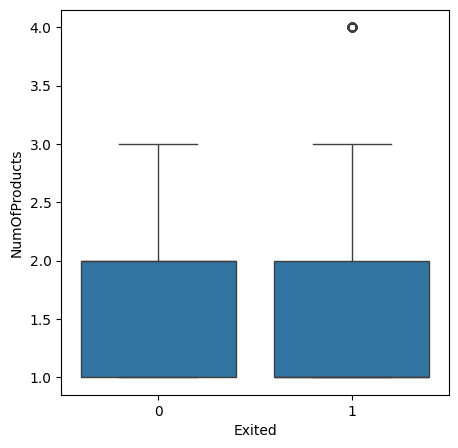

In [201]:
plt.figure(figsize=(5,5))
sns.boxplot(y='NumOfProducts',x='Exited',data=df)
plt.show()

* NumOfProducts has a strong, non-linear association with Exited. Churn rates are moderate for 1 product (27.67%), lowest for 2 products (7.58%), and extremely high for 3 (83.33%) and 4 products (100%).
* Customers with 2 products are least likely to churn, while those with 3 or 4 products are almost certain to leave, indicating a U-shaped relationship between product count and churn.
* The bank should encourage customers with 1 product to adopt a second product to boost loyalty, while addressing the high churn among those with 3 or 4 products by simplifying offerings or resolving product-specific dissatisfaction.

#### EstimatedSalary and Exited

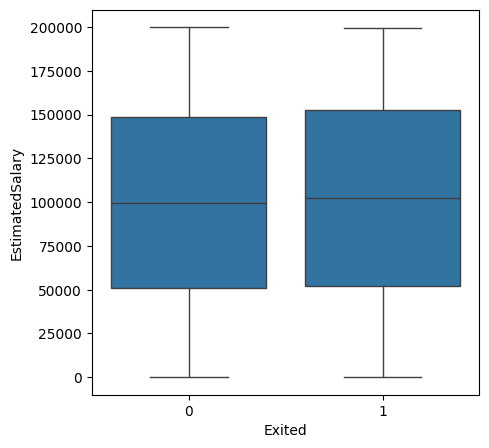

In [202]:
plt.figure(figsize=(5,5))
sns.boxplot(y='EstimatedSalary',x='Exited',data=df)
plt.show()

* EstimatedSalary has a very weak association with Exited. Churned customers have a slightly higher average salary (101,465.67) compared to those who stayed (99,687.55), but churn rates across salary ranges are stable at ~20.3%–20.4%, matching the overall rate (20.37%).
* Estimated salary has negligible impact on churn behavior, indicating that income level isn’t a significant driver of customer retention or departure.
* Retention strategies shouldn’t focus on salary levels, as they don’t significantly influence churn. Instead, prioritize factors like engagement (IsActiveMember) or product usage (NumOfProducts) that show stronger associations with churn.

#### Correlation between all the variables

In [203]:
# defining the list of numerical columns
cols_list = ["NumOfProducts","Age","Tenure","Balance","EstimatedSalary", 'Exited']

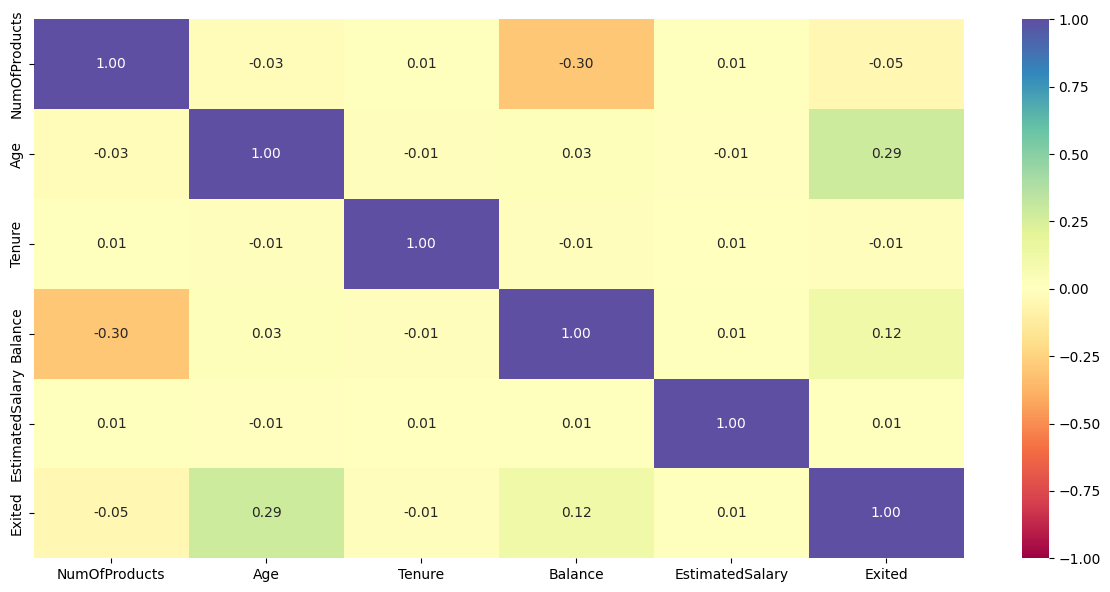

In [204]:
plt.figure(figsize=(15, 7))
sns.heatmap(df[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

* Age (0.29): Strongest predictor among these variables, with older customers more likely to churn.
* NumOfProducts (-0.05): Moderate predictor, though the relationship is non-linear (2 products reduce churn, 3–4 increase it).
* Balance (0.12): Weak positive correlation, with higher balances linked to higher churn.
* EstimatedSalary (0.01): very weak positive correlation
* Tenure (-0.01), EstimatedSalary (0.01): Negligible impact on churn.

* Age vs. Balance (0.03) show positive relationships.
* Most other pairs (e.g., EstimatedSalary vs. Tenure) show negligible correlations.

* For churn prediction, focus on Age, NumOfProducts, EstimatedSalary, and Balance as they show the strongest associations with Exited.
* EstimatedSalary and Tenure have minimal impact and might be less useful in predictive models.
* The non-linear relationship between NumOfProducts and Exited suggests that it may need special treatment (e.g., categorical encoding) in modeling.

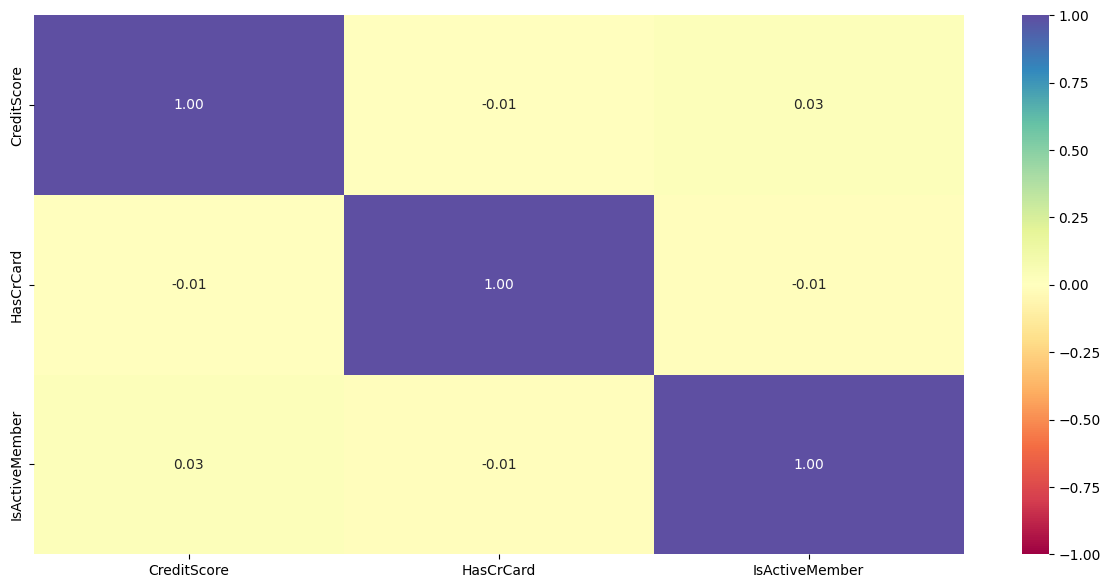

In [205]:
# defining the list of numerical columns
cols_list = ["CreditScore","HasCrCard","IsActiveMember"]
plt.figure(figsize=(15, 7))
sns.heatmap(df[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

### To jump back to the EDA summary section, click <a href = #link2>here</a>.